# Detector de voz sintética em inglês: baseline

> **Um detector que classifica se uma voz em inglês foi gerada por IA, para alertar contra golpes de clonagem de voz e evitar que ouvintes e sistemas confiem em um áudio que finge ser uma pessoa real.**

**Objetivo deste notebook:** treinar e avaliar o primeiro modelo do projeto (o *baseline*): uma CNN pequena que recebe 4 segundos de áudio e diz se a voz é real (0) ou falsa (1). Ele serve de referência: as próximas versões (com augmentation, mais dados e modelos maiores) precisam ganhar dele.

**Como o notebook está organizado:**

1. **Introdução** (esta célula).
2. **Configuração:** todos os hiperparâmetros numa célula só, com a justificativa de cada um.
3. **Mapa do banco:** de onde vêm os áudios, como foram rotulados e divididos, o que foi excluído e por quê.
4. **Visualização:** contagens, durações, formas de onda, espectrogramas e áudios para ouvir.
5. **Análise exploratória:** desbalanceamento e atalhos que o modelo poderia aprender no lugar da voz sintética.
6. **Treinamento do baseline:** amostragem balanceada, pipeline de áudio, CNN, early stopping.
7. **Avaliação:** validação e cada banco de teste, separadamente, uma única vez.
8. **Conclusões:** o que funcionou, onde falhou, limitações, próximos passos e dúvidas em aberto.

**Base teórica.** Usamos o que foi ensinado na trilha de Trainees da liga (aulas 3 a 10: classificação e métricas, MLP, treino com Adam, validação, regularização com dropout e early stopping, CNNs com convolução e pooling). Sempre que algo vem **de fora da trilha**, aparece um aviso assim:

> ⚠️ **Fora da trilha:** explicação curta do que é e por que foi usado.

Resumo do que vem de fora da trilha (cada item é explicado onde aparece):

| item | onde | por que precisamos |
|:--|:--|:--|
| Áudio, reamostragem e espectrograma mel (`torchaudio`, `soundfile`, `miniaudio`) | seções 2, 4, 6 | a trilha trabalha com imagens; aqui o áudio vira uma "imagem" (espectrograma) para a CNN |
| Classe `Dataset` em `src/dataset.py` | seção 2 e 6 | o `DataLoader` com vários processos no Windows só funciona se a classe estiver num arquivo `.py` |
| BatchNorm | seção 6 | estabiliza o treino da CNN (pedido no enunciado do projeto) |
| `BCEWithLogitsLoss` | seção 6 | é a entropia cruzada binária da Aula 3 com a sigmoide embutida, numericamente mais estável |
| Amostragem balanceada por fonte e gerador | seção 6 | a trilha só alerta para o desbalanceamento; não ensina como tratar |
| Curva ROC, AUC e EER (`scikit-learn`) | seções 5 e 7 | métricas padrão de detecção de deepfake, que não dependem da proporção real/fake |

## 2. Configuração

**O que faz:** importa as bibliotecas, define todos os hiperparâmetros numa célula só, fixa a seed e detecta a GPU.
**Por quê:** com tudo num lugar, dá para reproduzir o experimento e mudar um valor sem caçar pelo notebook.

**Instalação do PyTorch** (feita uma vez, no `env`, com Python 3.13 e driver NVIDIA com CUDA 13.3):

```powershell
env\Scripts\activate
pip install torch torchaudio --index-url https://download.pytorch.org/whl/cu130
pip install matplotlib scikit-learn ipykernel nbclient nbformat nbconvert miniaudio
```

Isso instalou `torch 2.14.1+cu130` e `torchaudio 2.11.0+cu130` (rodas para CUDA 13.0, que funcionam no driver 13.3). As versões foram acrescentadas ao `requirements.txt`.

**`QUICK`:** com `QUICK = True`, o notebook roda com poucas centenas de áudios e 2 épocas, só para testar de ponta a ponta em poucos minutos. Com `QUICK = False`, faz o treino e a avaliação completos.

**Justificativa de cada hiperparâmetro:**

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `SEED` | 42 | fixa os sorteios para o resultado ser reproduzível (a mesma seed do manifest) |
| `SAMPLE_RATE` | 16 kHz | a maioria dos bancos já está em 16 kHz; reamostrar para cima não cria informação, e uma taxa única elimina o atalho da taxa de amostragem |
| mono | 1 canal | todos os áudios já são mono; a média dos canais garante isso mesmo se aparecer um estéreo |
| `CROP_S` | 4 s | a mediana de duração da maioria dos bancos fica entre 3 e 5,5 s; 4 s pega a maior parte da fala e dá uma entrada de tamanho fixo para a CNN |
| `N_MELS` | 64 | resolução suficiente na faixa de 0 a 8 kHz e uma entrada pequena (64 × 401) para uma CNN pequena |
| `N_FFT`, `WIN_LENGTH`, `HOP_LENGTH` | 512, 400 (25 ms), 160 (10 ms) | janelas de 25 ms com passo de 10 ms são o padrão em fala: curtas o bastante para a fala parecer estável dentro da janela |
| `BATCH_SIZE` | 64 | dentro da faixa de mini-batch da Aula 6 (32 a 256), respeita o limite de 64 do projeto e cabe com folga nos 8 GB da GPU |
| `LR` | 0,001 | valor recomendado na Aula 6 para o Adam |
| `DROPOUT` | 0,3 | regularização da Aula 7; valor moderado, aplicado só antes da camada final |
| `MAX_EPOCHS` | 30 | teto de tempo; na prática o early stopping costuma parar antes |
| `PATIENCE` | 5 | early stopping da Aula 7: para se a EER da validação não melhora em 5 épocas seguidas |
| `PER_CLASS_PER_EPOCH` | 25.000 | 50.000 áudios por época (25 mil reais + 25 mil falsos) dão cerca de 1 minuto por época e, em 15 a 30 épocas, cobrem a maior parte do pool de treino |
| `VAL_MAX` | todos (51.189) | a validação escolhe o checkpoint, então usamos ela inteira para a EER ser estável |
| `TEST_MAX_PER_CLASS` | 5.000 | limita o tempo do teste; com 5 mil por classe, a incerteza da EER fica em torno de ±1 ponto percentual |
| `EDA_PER_CLASS` | 300 | áudios por classe e banco para medir o volume na análise exploratória (ler tudo levaria horas) |
| `NUM_WORKERS` | 8 | medimos cerca de 2.000 áudios/s com 8 processos de leitura; o gargalo é ler e decodificar áudio do disco, e mais processos disputam CPU e demoram para iniciar no Windows |

> ⚠️ **Fora da trilha (Windows + DataLoader):** com `num_workers > 0`, o `DataLoader` cria processos novos que precisam *importar* a classe `Dataset`. No Windows, uma classe definida dentro do notebook não pode ser importada por eles (erro de *pickling*). Por isso **só a classe `Dataset`** fica num arquivo pequeno, `src/dataset.py`, e é importada aqui. O resto do código está no notebook.

In [1]:
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torchaudio
import torchaudio.functional as AF
from IPython.display import Audio, Markdown, display
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.utils.data import DataLoader, Sampler

from src.dataset import AudioDataset   # só a classe Dataset mora fora do notebook (ver acima)

# ---------------- hiperparâmetros ----------------
QUICK = False                # True: teste rápido de ponta a ponta | False: treino completo

SEED = 42
SAMPLE_RATE = 16_000             # Hz, tudo é reamostrado para cá
CROP_S = 4.0                     # segundos por exemplo
N_MELS = 64
N_FFT = 512
WIN_LENGTH = 400                 # 25 ms a 16 kHz
HOP_LENGTH = 160                 # 10 ms a 16 kHz
BATCH_SIZE = 64
LR = 1e-3
DROPOUT = 0.3
MAX_EPOCHS = 30
PATIENCE = 5
PER_CLASS_PER_EPOCH = 25_000     # áudios reais (e também falsos) sorteados por época
VAL_MAX = None                   # None = validação inteira
TEST_MAX_PER_CLASS = 5_000       # teto de áudios por classe em cada banco de teste
EDA_PER_CLASS = 300              # áudios por classe e banco na análise de volume
NUM_WORKERS = 8

if QUICK:
    PER_CLASS_PER_EPOCH = 150
    MAX_EPOCHS = 2
    PATIENCE = 2
    VAL_MAX = 300
    TEST_MAX_PER_CLASS = 50
    EDA_PER_CLASS = 20
    NUM_WORKERS = 2

# ---------------- reprodutibilidade e dispositivo ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELS_DIR, RESULTS_DIR = Path("models"), Path("results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
SUFFIX = "_quick" if QUICK else ""
CKPT_PATH = MODELS_DIR / f"baseline_cnn{SUFFIX}.pt"
RESULTS_CSV = RESULTS_DIR / f"baseline_results{SUFFIX}.csv"

# ---------------- estilo dos gráficos ----------------
REAL_C, FAKE_C = "#2a78d6", "#eb6834"          # azul = real, laranja = fake (sempre)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 9})
pd.set_option("display.max_colwidth", 120)


def fmt(n):
    """Número inteiro com ponto de milhar (padrão brasileiro)."""
    return f"{int(n):,}".replace(",", ".")


def show_md(df, **kw):
    """Mostra uma tabela como markdown (o texto longo quebra a linha em vez de ser cortado)."""
    display(Markdown(df.to_markdown(**kw)))


print(f"QUICK = {QUICK}")
print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | dispositivo: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

QUICK = False
torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | dispositivo: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


## 3. Mapa do banco

Esta seção mostra **o banco de verdade**: o que tem nele, de onde veio cada parte, como foi rotulado e dividido, e as decisões tomadas no caminho. As informações vêm de `data/processed/manifest.parquet`, `docs/datasets.yaml` e `docs/audit_report.md`. No fim, as tabelas são salvas em `docs/dataset_overview.md` para quem quiser ler fora do notebook.

### 3.1 O manifest

**O que faz:** carrega o manifest (uma linha por áudio) e mostra 15 linhas sorteadas e o significado de cada coluna.
**Por quê:** o manifest é a única fonte da verdade sobre os dados: o notebook nunca procura arquivos por conta própria, só segue o que está nele.

In [2]:
df = pd.read_parquet("data/processed/manifest.parquet")
# No arquivo, os excluídos têm split vazio (role = "excluded"); aqui damos um nome a eles (só em memória).
assert df.loc[df.split.isna(), "role"].eq("excluded").all()
df["split"] = df["split"].fillna("excluded")
df["label"] = df["label"].astype(int)   # no arquivo é int8, que estoura em contas como 100 × n
print(f"{fmt(len(df))} áudios, {df.shape[1]} colunas")
display(df.sample(15, random_state=SEED))

756.350 áudios, 12 colunas


,path,label,source_dataset,generator,fake_type,speaker_id,language,original_split,role,split,duration_s,sample_rate
291656,data/raw/train_val_en/dfadd/DATASET_PflowTTS/DATASET_PflowTTS/train/p336_103_pflow.flac,1,dfadd,PflowTTS,full,vctk:p336,en,train,train_val,train,4.075125,16000
565388,data/raw/test_generalization/llamapartialspoof/R01TTS.0.b/dev01-gptsovits-partial-oa_6319_64726_000002_000001.wav,1,llamapartialspoof,gptsovits,partial,librispeech:6319,en,NaN,test_generalization,test,8.998062,16000
457530,data/raw/test_generalization/llamapartialspoof/R01TTS.0.a/dev01-cosyvoice-full_5895_34622_000028_000000.wav,1,llamapartialspoof,cosyvoice,full,librispeech:5895,en,NaN,test_generalization,test,12.445875,16000
101938,data/raw/train_val_en/asvspoof2019_la/LA/ASVspoof2019_LA_eval/flac/LA_E_3264683.flac,1,asvspoof2019_la,A18,full,asvspoof:LA_0048,en,eval,test_generalization,test,6.016625,16000
648570,data/raw/test_generalization/asvspoof2021_df/ASVspoof2021_DF_eval/flac/DF_E_2322835.flac,1,asvspoof2021_df,Task1-team02,full,vcc2020:TEF2,en,eval,test_generalization,test,2.880000,16000
156911,data/raw/train_val_en/dfadd/DATASET_VCTK_BONAFIDE/home/isjwdu/Work/Dataset/DFADD/DATASET_VCTK_BONAFIDE/train/p300_09...,0,dfadd,NaN,none,vctk:p300,en,train,train_val,train,4.279813,16000
402339,data/raw/real_en/librispeech/LibriSpeech/train-clean-100/8226/274369/8226-274369-0060.flac,0,librispeech,NaN,none,librispeech:8226,en,train-clean-100,train_val,train,14.565000,16000
756161,data/raw/test_ptbr/coraa/test/alip/80133_alip_.wav,0,coraa,NaN,none,NaN,pt,test,test_ptbr,test,0.800000,16000
444432,data/raw/test_generalization/llamapartialspoof/R01TTS.0.a/dev-clean_2277_149896_000025_000006.wav,0,llamapartialspoof,NaN,none,librispeech:2277,en,dev-clean,test_generalization,test,1.920000,16000
610245,data/raw/test_generalization/asvspoof2021_df/ASVspoof2021_DF_eval/flac/DF_E_2135002.flac,1,asvspoof2021_df,A09,full,asvspoof:LA_0004,en,eval,test_generalization,test,3.080000,16000


In [3]:
GLOSSARIO = pd.DataFrame([
    ("path", "caminho do arquivo de áudio, relativo à raiz do repositório"),
    ("label", "0 = real (voz humana gravada), 1 = fake (gerada ou modificada por IA)"),
    ("source_dataset", "banco de origem (mesmo nome do `docs/datasets.yaml`)"),
    ("generator", "sistema que gerou o fake (TTS, vocoder, código do ataque); vazio nos reais"),
    ("fake_type", "`none` (real), `full` (áudio todo falso) ou `partial` (só trechos falsos)"),
    ("speaker_id", "locutor, com prefixo do corpus de origem (ex.: `vctk:p225`); vazio quando o banco não informa"),
    ("language", "`en` ou `pt`"),
    ("original_split", "partição no banco original (ex.: `train`, `dev`, `eval`)"),
    ("role", "papel no projeto: `train_val`, `test_generalization`, `test_ptbr` ou `excluded`"),
    ("split", "uso neste projeto: `train`, `val` ou `test`; vazio nos excluídos (o notebook chama de `excluded`)"),
    ("duration_s", "duração em segundos (lida do cabeçalho do arquivo)"),
    ("sample_rate", "taxa de amostragem original do arquivo, em Hz"),
], columns=["coluna", "significado"])
show_md(GLOSSARIO, index=False)

| coluna         | significado                                                                                       |
|:---------------|:--------------------------------------------------------------------------------------------------|
| path           | caminho do arquivo de áudio, relativo à raiz do repositório                                       |
| label          | 0 = real (voz humana gravada), 1 = fake (gerada ou modificada por IA)                             |
| source_dataset | banco de origem (mesmo nome do `docs/datasets.yaml`)                                              |
| generator      | sistema que gerou o fake (TTS, vocoder, código do ataque); vazio nos reais                        |
| fake_type      | `none` (real), `full` (áudio todo falso) ou `partial` (só trechos falsos)                         |
| speaker_id     | locutor, com prefixo do corpus de origem (ex.: `vctk:p225`); vazio quando o banco não informa     |
| language       | `en` ou `pt`                                                                                      |
| original_split | partição no banco original (ex.: `train`, `dev`, `eval`)                                          |
| role           | papel no projeto: `train_val`, `test_generalization`, `test_ptbr` ou `excluded`                   |
| split          | uso neste projeto: `train`, `val` ou `test`; vazio nos excluídos (o notebook chama de `excluded`) |
| duration_s     | duração em segundos (lida do cabeçalho do arquivo)                                                |
| sample_rate    | taxa de amostragem original do arquivo, em Hz                                                     |

### 3.2 Funil: para onde vai cada áudio

**O que faz:** conta quantos áudios caem em treino, validação, teste e excluídos.
**Por quê:** é a visão geral do banco antes de qualquer detalhe.

,áudios,% do total,real,fake
split,,,,
train,260782,34.5,69122,191660
val,51189,6.8,15730,35459
test,416844,55.1,57096,359748
excluded,27535,3.6,11749,15786
total,756350,100.0,153697,602653


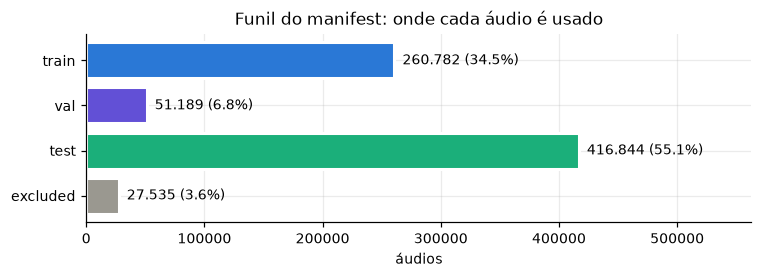

In [4]:
funil = (df["split"].value_counts().reindex(["train", "val", "test", "excluded"])
         .rename("áudios").to_frame())
funil["% do total"] = (100 * funil["áudios"] / len(df)).round(1)
funil["real"] = df[df.label == 0]["split"].value_counts()
funil["fake"] = df[df.label == 1]["split"].value_counts()
funil = funil.fillna(0).astype({"áudios": int, "real": int, "fake": int})
funil.loc["total"] = [len(df), 100.0, int((df.label == 0).sum()), int((df.label == 1).sum())]
display(funil)

fig, ax = plt.subplots(figsize=(7, 2.6))
parts = funil.drop("total")
ax.barh(parts.index[::-1], parts["áudios"][::-1], color=["#9a9890", CAT[2], CAT[6], CAT[0]],
        edgecolor="white", linewidth=2)
for i, (n, p) in enumerate(zip(parts["áudios"][::-1], parts["% do total"][::-1])):
    ax.text(n, i, f"  {fmt(n)} ({p:.1f}%)", va="center")
ax.set_xlim(0, parts["áudios"].max() * 1.35)
ax.set_xlabel("áudios")
ax.set_title("Funil do manifest: onde cada áudio é usado")
plt.tight_layout()
plt.show()

**Mais da metade do banco (55%) está reservada como teste, de propósito.** Os bancos de teste são inteiros e nunca vistos no treino: só assim dá para medir se o detector funciona com geradores, locutores e condições de gravação novos, que é o que acontece num golpe real.

### 3.3 Tabela por fonte

**O que faz:** junta, para cada banco, a origem, o papel no projeto, o idioma, o que ele contém, os geradores (com a contagem de áudios de cada um), como o rótulo foi obtido e as contagens por split e label.
**Por quê:** cada banco entra no projeto por um motivo diferente, e o resultado só faz sentido sabendo de onde vêm os dados.

As informações foram copiadas de `docs/datasets.yaml` e `docs/audit_report.md`. Onde esses documentos não dizem nada, está escrito **"não documentado"** (por exemplo, o ano de publicação, que não aparece em nenhum dos dois).

In [5]:
ND = "não documentado"
FONTES = {
    "asvspoof2019_la": dict(
        origem="https://datashare.ed.ac.uk/handle/10283/3336", licenca="ODC-By",
        papel="treino/validação (train+dev); a parte eval é teste de generalização **secundário**",
        idioma="en",
        rotulo="protocolos CM (`ASVspoof2019.LA.cm.*.txt`), coluna KEY: bonafide → 0, spoof → 1"),
    "dfadd": dict(
        origem="https://huggingface.co/datasets/isjwdu/DFADD", licenca=ND,
        papel="treino/validação", idioma="en",
        rotulo="arquivos `{train,valid,test}.txt` (formato ASVspoof), coluna KEY: bonafide → 0, spoof → 1"),
    "shiftyspeech": dict(
        origem="https://huggingface.co/datasets/ash56/ShiftySpeech", licenca=ND,
        papel="treino/validação", idioma="en",
        rotulo="não há arquivo de rótulo: nome da pasta, `real_data_*` → 0 e `<vocoder>_*` → 1 (decisão do projeto)"),
    "codecfake_plus": dict(
        origem="https://huggingface.co/datasets/CodecFake/CodecFake_Plus_Dataset", licenca=ND,
        papel="treino/validação (só a parte CoSG)", idioma="en",
        rotulo="`CoSG_labels.txt`, última coluna: bonafide → 0, Spoof → 1"),
    "librispeech": dict(
        origem="https://www.openslr.org/12", licenca="CC BY 4.0",
        papel="treino/validação (só train-clean-100; dev-clean e test-clean excluídos)", idioma="en",
        rotulo="corpus de leitura de audiolivros, todo real → 0"),
    "in_the_wild": dict(
        origem="https://huggingface.co/datasets/mueller91/In-The-Wild", licenca=ND,
        papel="teste de generalização (principal)", idioma="en",
        rotulo="`meta.csv`, coluna label: bona-fide → 0, spoof → 1"),
    "llamapartialspoof": dict(
        origem="https://github.com/hieuthi/LlamaPartialSpoof", licenca=ND,
        papel="teste de generalização (principal)", idioma="en",
        rotulo="`label_R01TTS.0.{a,b}.txt` e prefixo do id: reais (LibriTTS dev/test-clean) → 0; `full` e `partial` → 1"),
    "asvspoof2021_df": dict(
        origem="https://zenodo.org/records/4835108", licenca=ND,
        papel="teste de generalização **secundário** (só a parte 1 de 4)", idioma="en",
        rotulo="`keys/DF/CM/trial_metadata.txt`, coluna 6: bonafide → 0, spoof → 1"),
    "brspeech_df": dict(
        origem="https://huggingface.co/datasets/AKCIT-Deepfake/BRSpeech-DF", licenca="Apache-2.0",
        papel="teste pt (principal)", idioma="pt (mistura pt-BR e pt-PT, sem indicação por arquivo)",
        rotulo="coluna `label` do parquet (ClassLabel 0 = bonafide, 1 = spoof)"),
    "coraa": dict(
        origem="https://huggingface.co/datasets/gabrielrstan/CORAA-v1.1", licenca="CC BY-NC-ND 4.0",
        papel="teste pt-BR, só real: mede a taxa de falso alarme", idioma="pt-BR (os 326 `pt_pt` foram excluídos)",
        rotulo="corpus de reconhecimento de fala, todo real → 0"),
}
ORDEM_FONTES = list(FONTES)
usado = df[df.split != "excluded"]


def geradores_txt(src, max_itens=8):
    g = usado[(usado.source_dataset == src) & (usado.label == 1)]["generator"].value_counts()
    if g.empty:
        return "— (só real)"
    itens = [f"{k}: {fmt(v)}" for k, v in g.head(max_itens).items()]
    resto = f"; … e mais {len(g) - max_itens} geradores" if len(g) > max_itens else ""
    return "; ".join(itens) + resto


def contagens_txt(src):
    c = df[df.source_dataset == src].groupby(["split", "label"]).size()
    return "; ".join(f"{s}/{'real' if l == 0 else 'fake'}: {fmt(n)}" for (s, l), n in c.items())


linhas = []
for src, info in FONTES.items():
    labels = set(usado.loc[usado.source_dataset == src, "label"])
    contem = "real e fake" if labels == {0, 1} else ("só real" if labels == {0} else "só fake")
    linhas.append({"banco": src, "ano": ND, "origem": info["origem"], "licença": info["licenca"],
                   "papel": info["papel"], "idioma": info["idioma"], "contém": contem,
                   "geradores (áudios por gerador)": geradores_txt(src),
                   "como o rótulo foi obtido": info["rotulo"],
                   "contagens (split/label)": contagens_txt(src)})
TAB_FONTES = pd.DataFrame(linhas)
show_md(TAB_FONTES, index=False)

| banco             | ano             | origem                                                           | licença         | papel                                                                              | idioma                                                | contém      | geradores (áudios por gerador)                                                                                               | como o rótulo foi obtido                                                                                | contagens (split/label)                                                                                              |
|:------------------|:----------------|:-----------------------------------------------------------------|:----------------|:-----------------------------------------------------------------------------------|:------------------------------------------------------|:------------|:-----------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------|
| asvspoof2019_la   | não documentado | https://datashare.ed.ac.uk/handle/10283/3336                     | ODC-By          | treino/validação (train+dev); a parte eval é teste de generalização **secundário** | en                                                    | real e fake | A01: 7.516; A02: 7.516; A03: 7.516; A04: 7.516; A05: 7.516; A06: 7.516; A11: 4.914; A14: 4.914; … e mais 11 geradores        | protocolos CM (`ASVspoof2019.LA.cm.*.txt`), coluna KEY: bonafide → 0, spoof → 1                         | excluded/real: 838; test/real: 7.355; test/fake: 63.882; train/real: 5.128; train/fake: 45.096                       |
| dfadd             | não documentado | https://huggingface.co/datasets/isjwdu/DFADD                     | não documentado | treino/validação                                                                   | en                                                    | real e fake | PflowTTS: 33.000; GradTTS: 32.700; NaturalSpeech2: 32.700; StyleTTS2: 32.700; MatchaTTS: 32.400                              | arquivos `{train,valid,test}.txt` (formato ASVspoof), coluna KEY: bonafide → 0, spoof → 1               | train/real: 35.745; train/fake: 131.700; val/real: 8.710; val/fake: 31.800                                           |
| shiftyspeech      | não documentado | https://huggingface.co/datasets/ash56/ShiftySpeech               | não documentado | treino/validação                                                                   | en                                                    | real e fake | hifigan: 5.864; vocos: 5.864; wavegrad: 5.864                                                                                | não há arquivo de rótulo: nome da pasta, `real_data_*` → 0 e `<vocoder>_*` → 1 (decisão do projeto)     | excluded/real: 5.262; excluded/fake: 15.786; train/real: 4.707; train/fake: 14.121; val/real: 1.157; val/fake: 3.471 |
| codecfake_plus    | não documentado | https://huggingface.co/datasets/CodecFake/CodecFake_Plus_Dataset | não documentado | treino/validação (só a parte CoSG)                                                 | en                                                    | real e fake | MASKGCT: 576; CLAMTTS: 78; VALLE: 57; NS3: 32; SIMPLESPEECH1: 32; SIMPLESPEECH2: 31; GPST: 30; NS2: 23; … e mais 9 geradores | `CoSG_labels.txt`, última coluna: bonafide → 0, Spoof → 1                                               | train/real: 702; train/fake: 743; val/real: 164; val/fake: 188                                                       |
| librispeech       | não documentado | https://www.openslr.org/12                                       | CC BY 4.0       | treino/validação (só train-clean-100; dev-clean e test-clean excluídos)            | en                                                    | só real     | — (só real)                                                                                                                  | corpus de leitura de audiolivros, todo real → 0                                                         | excluded/real: 5.323; train/real: 22.840; val/real: 5.699                                                            |
| in_the_wild       | não documentado | https://huggingface.co/datasets/mueller91/In-The-Wild            | não documentado | teste de generalização (principal)                                                 | en                                                    | real e fake | unknown: 11.816                                                                                                              | `meta.csv`, coluna label: bona-fide → 0, spoof → 1                                                      | test/real: 19.963; test/fake: 11.816                                                                                 |
| llamapartialspoof | não documentado | https://github.com/hieuthi/LlamaPartialSpoof                     | não documentado | teste de generalização (principal)                                                 | en                                                    | real e fake | elevenlab: 21.738; gptsovits: 21.738; ljjets: 21.738; yourtts: 21.738; xttsv2: 21.729; cosyvoice: 21.362                     | `label_R01TTS.0.{a,b}.txt` e prefixo do id: reais (LibriTTS dev/test-clean) → 0; `full` e `partial` → 1 | test/real: 10.573; test/fake: 130.043                                                                                |
| asvspoof2021_df   | não documentado | https://zenodo.org/records/4835108                               | não documentado | teste de generalização **secundário** (só a parte 1 de 4)                          | en                                                    | real e fake | A11: 2.865; A10: 2.837; A16: 2.817; A12: 2.815; A13: 2.808; A07: 2.803; A08: 2.771; A17: 2.759; … e mais 102 geradores       | `keys/DF/CM/trial_metadata.txt`, coluna 6: bonafide → 0, spoof → 1                                      | test/real: 5.535; test/fake: 147.420                                                                                 |
| brspeech_df       | não documentado | https://huggingface.co/datasets/AKCIT-Deepfake/BRSpeech-DF       | Apache-2.0      | teste pt (principal)                                                               | pt (mistura pt-BR e pt-PT, sem indicação por arquivo) | real e fake | toucantts: 1.320; xtts: 1.320; f5tts: 1.316; yourtts: 1.316; fish-speech: 1.315                                              | coluna `label` do parquet (ClassLabel 0 = bonafide, 1 = spoof)                                          | test/real: 1.320; test/fake: 6.587                                                                                   |
| coraa             | não documentado | https://huggingface.co/datasets/gabrielrstan/CORAA-v1.1          | CC BY-NC-ND 4.0 | teste pt-BR, só real: mede a taxa de falso alarme                                  | pt-BR (os 326 `pt_pt` foram excluídos)                | só real     | — (só real)                                                                                                                  | corpus de reconhecimento de fala, todo real → 0                                                         | excluded/real: 326; test/real: 12.350                                                                                |

Contagens por banco, split e label numa tabela só (é a mesma da seção 4.1 do `audit_report.md`):

In [6]:
TAB_CONTAGENS = (df.assign(grupo=df["split"] + "/" + df["label"].map({0: "real", 1: "fake"}))
                   .pivot_table(index="source_dataset", columns="grupo", values="path",
                                aggfunc="count", fill_value=0)
                   .reindex(ORDEM_FONTES))
TAB_CONTAGENS = TAB_CONTAGENS[[c for c in ["train/real", "train/fake", "val/real", "val/fake",
                                           "test/real", "test/fake", "excluded/real", "excluded/fake"]
                               if c in TAB_CONTAGENS]]
TAB_CONTAGENS.loc["total"] = TAB_CONTAGENS.sum()
display(TAB_CONTAGENS)

# lista completa de geradores (o asvspoof2021_df tem 110 e não cabe na tabela acima)
TAB_GERADORES = (usado[usado.label == 1].groupby(["source_dataset", "generator"]).size()
                 .rename("áudios").reset_index())
print(f"{len(TAB_GERADORES)} pares banco × gerador (lista completa salva em docs/dataset_overview.md)")

grupo,train/real,train/fake,val/real,val/fake,test/real,test/fake,excluded/real,excluded/fake
source_dataset,,,,,,,,
asvspoof2019_la,5128,45096,0,0,7355,63882,838,0
dfadd,35745,131700,8710,31800,0,0,0,0
shiftyspeech,4707,14121,1157,3471,0,0,5262,15786
codecfake_plus,702,743,164,188,0,0,0,0
librispeech,22840,0,5699,0,0,0,5323,0
in_the_wild,0,0,0,0,19963,11816,0,0
llamapartialspoof,0,0,0,0,10573,130043,0,0
asvspoof2021_df,0,0,0,0,5535,147420,0,0
brspeech_df,0,0,0,0,1320,6587,0,0


166 pares banco × gerador (lista completa salva em docs/dataset_overview.md)


### 3.4 Como os rótulos foram padronizados

Cada banco escreve o rótulo de um jeito (`bonafide`/`spoof`, `bona-fide`, `Spoof`, nome de pasta, 0/1…). O `scripts/build_manifest.py` converteu todos para **um só padrão: 0 = real, 1 = fake**, conforme a coluna "como o rótulo foi obtido" da tabela acima. Um áudio é **fake** quando qualquer parte dele foi gerada ou modificada por IA: TTS, conversão de voz, resíntese por vocoder ou codec, e também os áudios **parcialmente** falsos do LlamaPartialSpoof (`fake_type = partial`).

### 3.5 Divisão treino/validação por locutor

**O que faz:** confere com um `assert` que nenhum locutor aparece ao mesmo tempo em treino e validação.
**Por quê:** se o mesmo locutor estiver nos dois, o modelo pode acertar a validação só por reconhecer a voz e a gravação daquela pessoa, e não por detectar a síntese. Isso infla o resultado e leva a escolher o checkpoint errado (é o vazamento de dados da Aula 7, como "o mesmo paciente no treino e no teste").

Como foi feito (`audit_report.md`, seção 4): os locutores de cada banco do pool são sorteados (seed 42) e vão para a validação até chegar a cerca de 20% dos áudios do banco. Exceções: o ASVspoof 2019 (train+dev) vai **inteiro** para o treino, e no CodecFake+ (sem locutor) o grupo é a página de demo de onde o áudio veio.

In [7]:
spk_train = set(df.loc[df.split == "train", "speaker_id"].dropna())
spk_val = set(df.loc[df.split == "val", "speaker_id"].dropna())
spk_test = set(df.loc[df.split == "test", "speaker_id"].dropna())
assert not (spk_train & spk_val), "há locutor em train e val ao mesmo tempo!"
assert not ((spk_train | spk_val) & spk_test), "há locutor do pool de treino num banco de teste!"

# CodecFake+ não tem locutor: o grupo é a demo (coluna generator nos fakes); conferimos pelo nome do arquivo
cf = df[df.source_dataset == "codecfake_plus"].copy()
cf["demo"] = cf["path"].str.extract(r"/([^/]+)_\d+\.wav$")[0]
assert not (set(cf.loc[cf.split == "train", "demo"]) & set(cf.loc[cf.split == "val", "demo"]))

print(f"OK: {fmt(len(spk_train))} locutores em train, {fmt(len(spk_val))} em val, "
      f"{fmt(len(spk_test))} nos testes, nenhum em comum (por speaker_id).")

OK: 382 locutores em train, 86 em val, 236 nos testes, nenhum em comum (por speaker_id).


O teste por `speaker_id` passa. A ressalva é o **VCTK compartilhado**: o ASVspoof anonimiza os locutores (`LA_xxxx`) e eles vêm do mesmo corpus VCTK que os reais do DFADD. Não há como casar os ids, então pode haver locutores em comum que o `assert` não enxerga. Por isso o ASVspoof 2019 eval e o ASVspoof 2021 DF são **testes secundários** (ver 3.6).

### 3.6 Bancos de teste separados e exclusões

Os bancos de teste ficam **completamente separados**: nunca entram no treino, nunca entram na escolha de hiperparâmetros nem do checkpoint (isso é papel da validação) e são avaliados **uma única vez**, no fim (Aula 7: o teste é usado uma vez, no final). Se olhássemos o teste para decidir alguma coisa, ele deixaria de medir generalização.

| banco de teste | tipo | o que mede |
|:--|:--|:--|
| in_the_wild | principal | deepfakes reais tirados da internet (celebridades e políticos), gerador desconhecido |
| llamapartialspoof | principal | geradores modernos (inclusive ElevenLabs e XTTS) e fakes **parciais** |
| brspeech_df | principal (pt) | outro idioma (português) e geradores modernos |
| asvspoof2019_la (eval) | **secundário** | ataques A07–A19, que não estão no treino; pode ter locutores do treino via VCTK |
| asvspoof2021_df (parte 1) | **secundário** | ataques novos e compressão de codec; mesma ressalva do VCTK |
| coraa | falso alarme (pt-BR) | só voz real em português: mede quantas vozes reais o modelo acusa de fake |

In [8]:
EXCLUSOES = pd.DataFrame([
    ("librispeech dev-clean + test-clean", 5323,
     "mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof (LibriTTS dev/test-clean)"),
    ("shiftyspeech, locutores do LlamaPartialSpoof", 21048,
     "5.262 reais + 15.786 fakes de 79 locutores que também estão no teste LlamaPartialSpoof: vazamento de locutor e de gravação"),
    ("asvspoof2019_la, áudios de cadastro do ASV", 838, "fora do protocolo de detecção (CM), sem uso aqui"),
    ("coraa `pt_pt`", 326, "português europeu, fora do teste pt-BR"),
], columns=["o que", "linhas", "motivo"])
assert EXCLUSOES["linhas"].sum() == (df.split == "excluded").sum()
show_md(EXCLUSOES, index=False)
print(f"Total excluído: {fmt(EXCLUSOES['linhas'].sum())} linhas (confere com o manifest).")

| o que                                        |   linhas | motivo                                                                                                                     |
|:---------------------------------------------|---------:|:---------------------------------------------------------------------------------------------------------------------------|
| librispeech dev-clean + test-clean           |     5323 | mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof (LibriTTS dev/test-clean)                                  |
| shiftyspeech, locutores do LlamaPartialSpoof |    21048 | 5.262 reais + 15.786 fakes de 79 locutores que também estão no teste LlamaPartialSpoof: vazamento de locutor e de gravação |
| asvspoof2019_la, áudios de cadastro do ASV   |      838 | fora do protocolo de detecção (CM), sem uso aqui                                                                           |
| coraa `pt_pt`                                |      326 | português europeu, fora do teste pt-BR                                                                                     |

Total excluído: 27.535 linhas (confere com o manifest).


### 3.7 Tabela de decisões

**O que faz:** lista as decisões de dados e de treino, o motivo de cada uma e a alternativa que descartamos.
**Por quê:** cada decisão muda o que o número final significa; deixá-las escritas evita que alguém compare resultados que não são comparáveis.

In [9]:
DECISOES = pd.DataFrame([
    ("Dividir treino/validação **por locutor**",
     "o modelo não pode acertar por reconhecer a voz de quem já ouviu",
     "Dividir **por arquivo**: descartada, porque o mesmo locutor cai em treino e validação e infla o resultado"),
    ("Bancos de teste **inteiros e separados** do treino",
     "medem generalização para geradores, locutores e gravações nunca vistos",
     "**Misturar tudo e dividir em 3 partes**: descartada, porque os mesmos geradores nos 3 conjuntos não medem generalização"),
    ("Não usar o **In-the-Wild** no treino",
     "é o único teste com deepfakes reais tirados da internet",
     "Treinar com ele: descartada, perderíamos a medida mais próxima de um golpe real"),
    ("**ASVspoof 2019** (train+dev) inteiro em train",
     "os locutores são anônimos e podem ser os mesmos do VCTK do DFADD; um bloco só evita vazamento treino↔validação dentro do próprio ASVspoof",
     "Dividir os 40 locutores do ASVspoof entre train e val: descartada, a validação herdaria ataques A01–A06 com locutores possivelmente repetidos"),
    ("Excluir **LibriSpeech dev/test-clean**",
     "são a mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof",
     "Usá-los como reais extras no treino: descartada, vazaria para o teste"),
    ("Excluir os **locutores do LlamaPartialSpoof no ShiftySpeech**",
     "21.048 áudios com os mesmos locutores e gravações do teste",
     "Mantê-los: descartada, inflaria o resultado no LlamaPartialSpoof"),
    ("Excluir o **CORAA pt-PT**",
     "o teste de falso alarme é de português brasileiro",
     "Manter os 326: descartada, misturaria outra variedade sem poder separar no resultado"),
    ("**Reamostrar tudo para 16 kHz** no carregamento",
     "a maioria dos bancos já está em 16 kHz, e uma taxa única elimina o atalho do BRSpeech-DF (real 48 kHz, fake 24 kHz)",
     "Usar a taxa original de cada arquivo: descartada, a taxa (e a banda) viraria uma pista do rótulo"),
    ("Recorte de **4 s**, aleatório no treino e central na validação/teste; áudio curto é **repetido**",
     "entrada de tamanho fixo; o recorte aleatório mostra trechos diferentes a cada época; repetir não cria silêncio artificial",
     "Completar com zeros: descartada, a quantidade de silêncio contaria a duração do áudio, que difere entre real e fake"),
    ("Log-mel **padronizado por exemplo** (média 0, desvio 1)",
     "tira o volume do jogo: um ganho no áudio vira uma constante no log-mel, que a padronização remove",
     "Usar o log-mel cru: descartada, o volume difere entre bancos e entre real/fake e seria um atalho"),
    ("Amostra **50/50 real/fake com teto por fonte e por gerador, sorteada de novo a cada época**",
     "o pool é 73% fake e o DFADD sozinho é 64% do treino; assim nenhuma fonte ou gerador (como os antigos do ASVspoof 2019) domina, e ao longo das épocas o modelo vê a maior parte do pool",
     "**Todos os áudios com pesos de classe**: alternativa válida para o real/fake, mas não resolve a dominância do DFADD nem dos geradores (64% dos gradientes continuariam vindo de um banco) e deixa as épocas 5 vezes mais longas"),
    ("Escolher o checkpoint pela **menor EER na validação**",
     "a EER não depende da proporção real/fake nem de um limiar fixo",
     "Pela acurácia: descartada, a validação é 69% fake e a acurácia muda com essa proporção; pela perda: mede a calibração, não a separação"),
    ("**Sem augmentation** no baseline",
     "primeiro medimos o modelo puro, para saber depois quanto a augmentation ajuda",
     "Já começar com augmentation de codec/ruído: fica para a próxima etapa, senão não há referência"),
], columns=["O que decidimos", "Por quê", "Alternativa descartada e por quê"])
show_md(DECISOES, index=False)

| O que decidimos                                                                                  | Por quê                                                                                                                                                                                | Alternativa descartada e por quê                                                                                                                                                                                                |
|:-------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Dividir treino/validação **por locutor**                                                         | o modelo não pode acertar por reconhecer a voz de quem já ouviu                                                                                                                        | Dividir **por arquivo**: descartada, porque o mesmo locutor cai em treino e validação e infla o resultado                                                                                                                       |
| Bancos de teste **inteiros e separados** do treino                                               | medem generalização para geradores, locutores e gravações nunca vistos                                                                                                                 | **Misturar tudo e dividir em 3 partes**: descartada, porque os mesmos geradores nos 3 conjuntos não medem generalização                                                                                                         |
| Não usar o **In-the-Wild** no treino                                                             | é o único teste com deepfakes reais tirados da internet                                                                                                                                | Treinar com ele: descartada, perderíamos a medida mais próxima de um golpe real                                                                                                                                                 |
| **ASVspoof 2019** (train+dev) inteiro em train                                                   | os locutores são anônimos e podem ser os mesmos do VCTK do DFADD; um bloco só evita vazamento treino↔validação dentro do próprio ASVspoof                                              | Dividir os 40 locutores do ASVspoof entre train e val: descartada, a validação herdaria ataques A01–A06 com locutores possivelmente repetidos                                                                                   |
| Excluir **LibriSpeech dev/test-clean**                                                           | são a mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof                                                                                                                  | Usá-los como reais extras no treino: descartada, vazaria para o teste                                                                                                                                                           |
| Excluir os **locutores do LlamaPartialSpoof no ShiftySpeech**                                    | 21.048 áudios com os mesmos locutores e gravações do teste                                                                                                                             | Mantê-los: descartada, inflaria o resultado no LlamaPartialSpoof                                                                                                                                                                |
| Excluir o **CORAA pt-PT**                                                                        | o teste de falso alarme é de português brasileiro                                                                                                                                      | Manter os 326: descartada, misturaria outra variedade sem poder separar no resultado                                                                                                                                            |
| **Reamostrar tudo para 16 kHz** no carregamento                                                  | a maioria dos bancos já está em 16 kHz, e uma taxa única elimina o atalho do BRSpeech-DF (real 48 kHz, fake 24 kHz)                                                                    | Usar a taxa original de cada arquivo: descartada, a taxa (e a banda) viraria uma pista do rótulo                                                                                                                                |
| Recorte de **4 s**, aleatório no treino e central na validação/teste; áudio curto é **repetido** | entrada de tamanho fixo; o recorte aleatório mostra trechos diferentes a cada época; repetir não cria silêncio artificial                                                              | Completar com zeros: descartada, a quantidade de silêncio contaria a duração do áudio, que difere entre real e fake                                                                                                             |
| Log-mel **padronizado por exemplo** (média 0, desvio 1)                                          | tira o volume do jogo: um ganho no áudio vira uma constante no log-mel, que a padronização remove                                                                                      | Usar o log-mel cru: descartada, o volume difere entre bancos e entre real/fake e seria um atalho                                                                                                                                |
| Amostra **50/50 real/fake com teto por fonte e por gerador, sorteada de novo a cada época**      | o pool é 73% fake e o DFADD sozinho é 64% do treino; assim nenhuma fonte ou gerador (como os antigos do ASVspoof 2019) domina, e ao longo das épocas o modelo vê a maior parte do pool | **Todos os áudios com pesos de classe**: alternativa válida para o real/fake, mas não resolve a dominância do DFADD nem dos geradores (64% dos gradientes continuariam vindo de um banco) e deixa as épocas 5 vezes mais longas |
| Escolher o checkpoint pela **menor EER na validação**                                            | a EER não depende da proporção real/fake nem de um limiar fixo                                                                                                                         | Pela acurácia: descartada, a validação é 69% fake e a acurácia muda com essa proporção; pela perda: mede a calibração, não a separação                                                                                          |
| **Sem augmentation** no baseline                                                                 | primeiro medimos o modelo puro, para saber depois quanto a augmentation ajuda                                                                                                          | Já começar com augmentation de codec/ruído: fica para a próxima etapa, senão não há referência                                                                                                                                  |

### 3.8 Salvar o mapa do banco em `docs/dataset_overview.md`

**O que faz:** grava as tabelas desta seção num arquivo markdown.
**Por quê:** para consultar o banco sem abrir o notebook (as 15 linhas sorteadas ficam só aqui, porque mudam a cada sorteio).

In [10]:
def to_md(t, index=False):
    return t.to_markdown(index=index)


partes = [
    "# Visão geral do banco de dados",
    "",
    "Gerado automaticamente pelo `notebook.ipynb` (seção 3) a partir de `data/processed/manifest.parquet`, "
    "`docs/datasets.yaml` e `docs/audit_report.md`. Não edite à mão: rode o notebook de novo.",
    "",
    "## Funil", "", to_md(funil, index=True), "",
    "Mais da metade do banco (55%) está reservada como teste, de propósito: os bancos de teste são inteiros "
    "e nunca vistos no treino, para medir generalização.",
    "", "## Glossário das colunas do manifest", "", to_md(GLOSSARIO), "",
    "## Tabela por fonte", "", to_md(TAB_FONTES), "",
    "## Contagens por banco, split e label", "", to_md(TAB_CONTAGENS, index=True), "",
    "## Exclusões", "", to_md(EXCLUSOES), "",
    "## Decisões", "", to_md(DECISOES), "",
    "## Geradores por banco (todos os splits usados)", "", to_md(TAB_GERADORES), "",
]
if not QUICK:   # o modo rápido não sobrescreve o arquivo oficial
    Path("docs/dataset_overview.md").write_text("\n".join(partes), encoding="utf-8")
    print("salvo em docs/dataset_overview.md")
else:
    print("QUICK = True: docs/dataset_overview.md não foi sobrescrito")

salvo em docs/dataset_overview.md


## 4. Visualização

### 4.1 Contagem por fonte, label e split

**O que faz:** um gráfico de barras por split, com reais e falsos de cada banco lado a lado.
**Por quê:** mostra de relance quais bancos alimentam cada etapa e onde uma classe é rara.

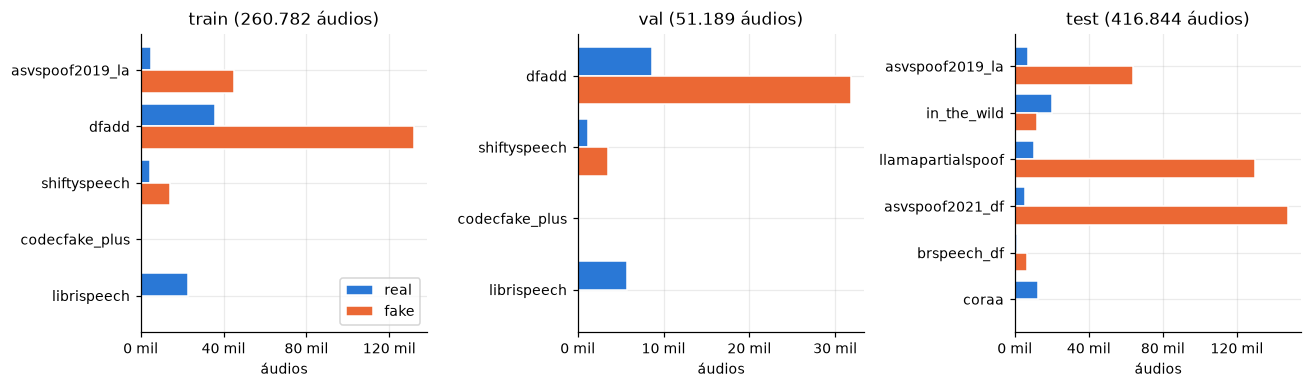

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
for ax, split in zip(axes, ["train", "val", "test"]):
    sub = df[df.split == split].groupby(["source_dataset", "label"]).size().unstack(fill_value=0)
    sub = sub.reindex([s for s in ORDEM_FONTES if s in sub.index]).reindex(columns=[0, 1], fill_value=0)
    y = np.arange(len(sub))
    ax.barh(y - 0.2, sub[0], 0.4, color=REAL_C, label="real", edgecolor="white", linewidth=1)
    ax.barh(y + 0.2, sub[1], 0.4, color=FAKE_C, label="fake", edgecolor="white", linewidth=1)
    ax.set_yticks(y, sub.index)
    ax.invert_yaxis()
    ax.set_title(f"{split} ({fmt(sub.values.sum())} áudios)")
    ax.set_xlabel("áudios")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f} mil")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Conclusão:** o treino é dominado pelo DFADD e pelo ASVspoof 2019, quase sempre com mais fakes que reais; a validação não tem ASVspoof 2019; nos testes, LlamaPartialSpoof e ASVspoof 2021 DF são quase só fake, e o CORAA é só real.

### 4.2 Duração por label

**O que faz:** histograma da duração dos áudios reais e falsos (sem os excluídos).
**Por quê:** se reais e falsos tiverem durações muito diferentes, o modelo pode aprender a "medir a duração" em vez de ouvir a voz.

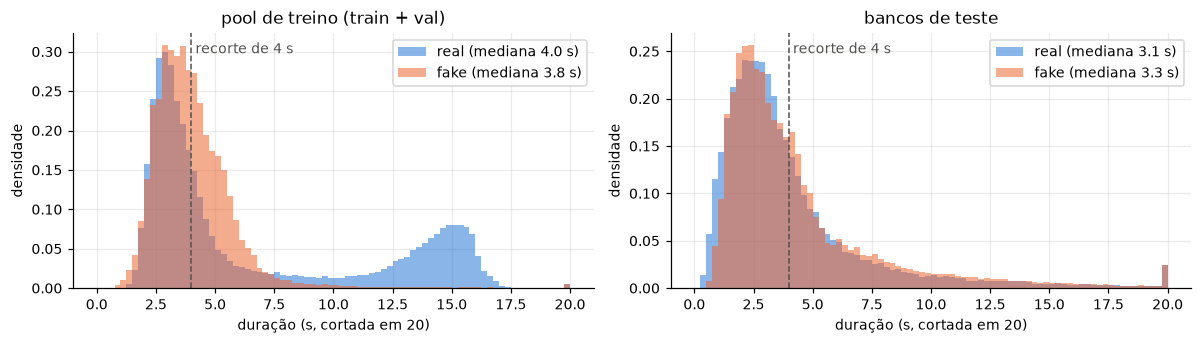

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
bins = np.linspace(0, 20, 81)
for ax, split_grp, titulo in [(axes[0], ["train", "val"], "pool de treino (train + val)"),
                              (axes[1], ["test"], "bancos de teste")]:
    sub = usado[usado.split.isin(split_grp)]
    for lab, cor, nome in [(0, REAL_C, "real"), (1, FAKE_C, "fake")]:
        d = sub.loc[sub.label == lab, "duration_s"].clip(upper=20)
        ax.hist(d, bins=bins, density=True, alpha=0.55, color=cor,
                label=f"{nome} (mediana {d.median():.1f} s)")
    ax.axvline(CROP_S, color="#52514e", ls="--", lw=1)
    ax.text(CROP_S, ax.get_ylim()[1] * 0.92, f" recorte de {CROP_S:.0f} s", color="#52514e")
    ax.set_title(titulo)
    ax.set_xlabel("duração (s, cortada em 20)")
    ax.set_ylabel("densidade")
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** no pool de treino os reais tendem a ser mais longos (o LibriSpeech, só real, tem mediana de 13,5 s); o recorte fixo de 4 s esconde boa parte dessa diferença, mas a duração continua sendo um risco de atalho (ver 5.3).

### 4.3 Forma de onda e espectrograma mel

**O que faz:** mostra, lado a lado, a forma de onda e o log-mel espectrograma de 2 áudios reais e 4 falsos de geradores diferentes, todos do pool de treino e já no formato que a CNN recebe (16 kHz, 4 s).
**Por quê:** é isso que o modelo "vê". O espectrograma mostra a energia de cada faixa de frequência ao longo do tempo, e é nele que aparecem marcas de síntese (bandas sem energia, harmônicos borrados, padrões repetidos do vocoder).

> ⚠️ **Fora da trilha (espectrograma mel):** o áudio é cortado em janelas de 25 ms; em cada janela, a transformada de Fourier mede a energia por frequência; as frequências são agrupadas em 64 faixas na escala mel (que imita o ouvido: mais detalhe nos graves) e passamos o log, porque o ouvido percebe volume em escala logarítmica. O resultado é uma "imagem" de 64 × 401 que uma CNN como as das Aulas 9 e 10 consegue processar.

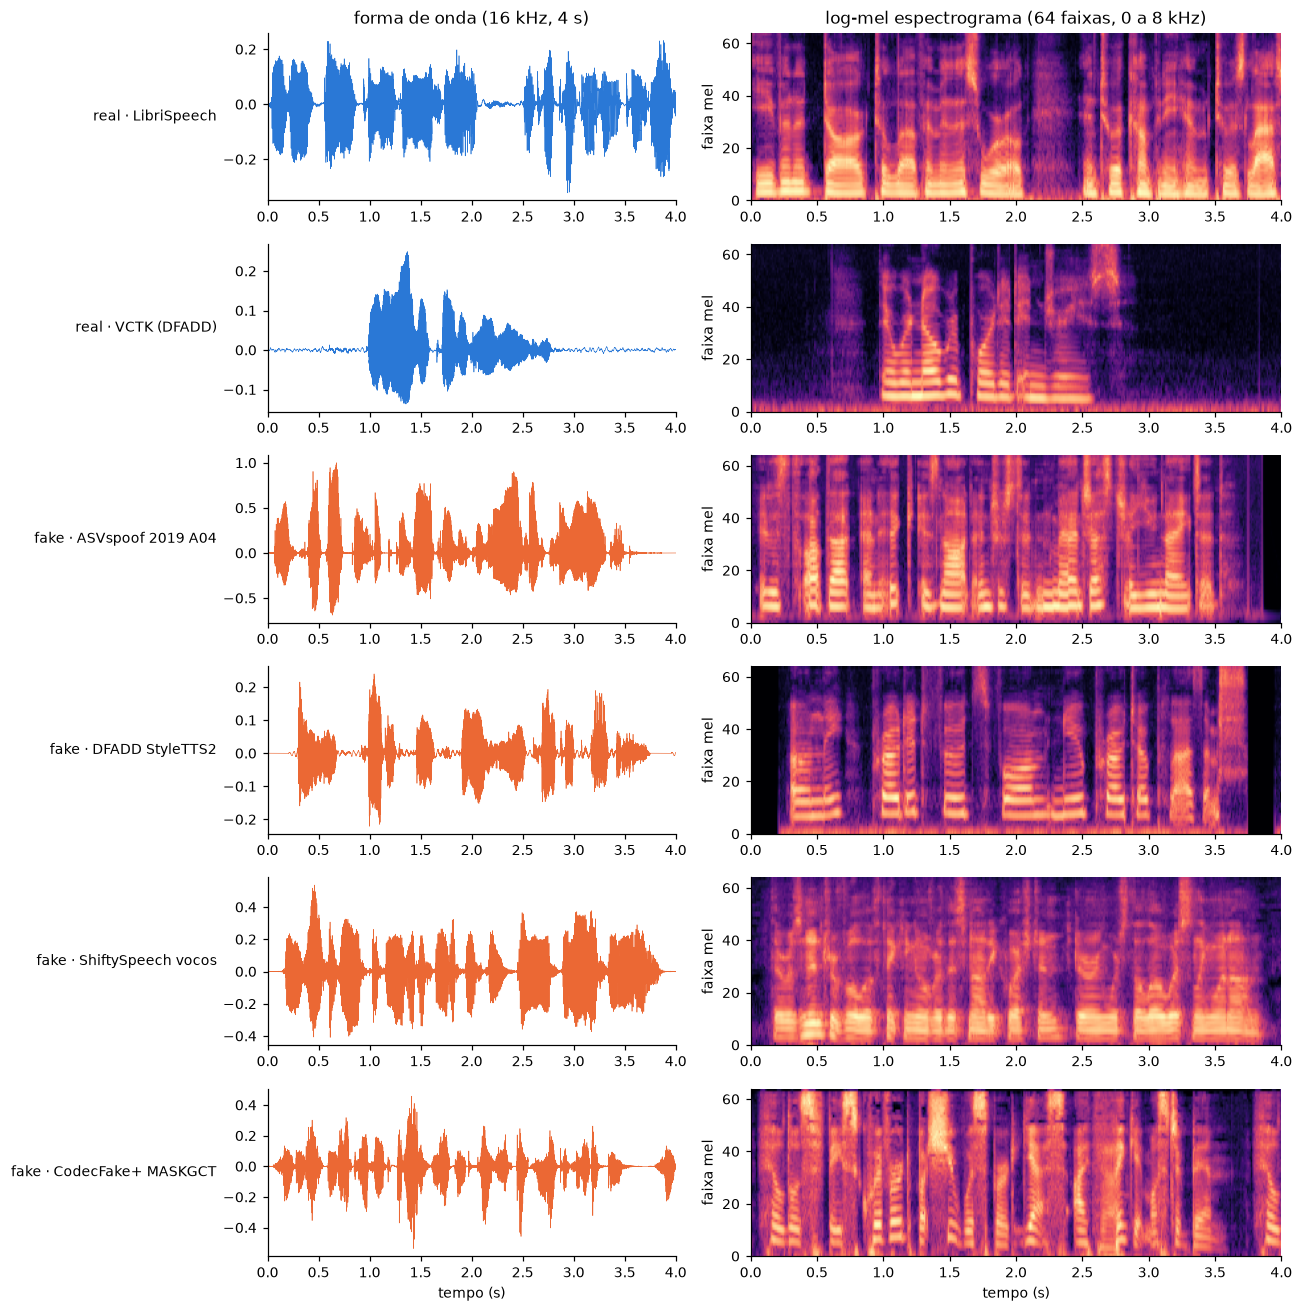

In [13]:
mel_cpu = torchaudio.transforms.MelSpectrogram(sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=WIN_LENGTH,
                                               hop_length=HOP_LENGTH, n_mels=N_MELS)


def carregar(row, mode="center"):
    """Um áudio do manifest no formato do modelo: mono, 16 kHz, 4 s."""
    ds = AudioDataset([row.path], [row.label], [row.sample_rate], [row.duration_s],
                      crop_s=CROP_S, target_sr=SAMPLE_RATE, mode=mode)
    return ds[0][0]


def exemplo(split, src, label, gen=None, seed=SEED):
    sub = df[(df.split == split) & (df.source_dataset == src) & (df.label == label)
             & (df.duration_s >= 3.5)]          # pelo menos ~4 s, para não aparecer repetido
    if gen is not None:
        sub = sub[sub.generator == gen]
    return sub.sample(1, random_state=seed).iloc[0]


EXEMPLOS = [
    ("real · LibriSpeech", exemplo("train", "librispeech", 0)),
    ("real · VCTK (DFADD)", exemplo("train", "dfadd", 0)),
    ("fake · ASVspoof 2019 A04", exemplo("train", "asvspoof2019_la", 1, "A04")),
    ("fake · DFADD StyleTTS2", exemplo("train", "dfadd", 1, "StyleTTS2")),
    ("fake · ShiftySpeech vocos", exemplo("train", "shiftyspeech", 1, "vocos")),
    ("fake · CodecFake+ MASKGCT", exemplo("train", "codecfake_plus", 1, "MASKGCT")),
]
fig, axes = plt.subplots(len(EXEMPLOS), 2, figsize=(12, 2.0 * len(EXEMPLOS)),
                         gridspec_kw={"width_ratios": [1, 1.3]})
t = np.arange(int(CROP_S * SAMPLE_RATE)) / SAMPLE_RATE
for (nome, row), (ax_w, ax_m) in zip(EXEMPLOS, axes):
    x = carregar(row)
    cor = REAL_C if row.label == 0 else FAKE_C
    ax_w.plot(t, x.numpy(), color=cor, lw=0.4)
    ax_w.set_xlim(0, CROP_S)
    ax_w.set_ylabel(nome, rotation=0, ha="right", va="center", fontsize=9)
    ax_w.grid(False)
    m = torch.log(mel_cpu(x) + 1e-6).numpy()
    ax_m.imshow(m, origin="lower", aspect="auto", cmap="magma", extent=[0, CROP_S, 0, N_MELS])
    ax_m.set_ylabel("faixa mel")
    ax_m.grid(False)
axes[0, 0].set_title("forma de onda (16 kHz, 4 s)")
axes[0, 1].set_title("log-mel espectrograma (64 faixas, 0 a 8 kHz)")
axes[-1, 0].set_xlabel("tempo (s)")
axes[-1, 1].set_xlabel("tempo (s)")
plt.tight_layout()
plt.show()

**Conclusão:** a olho, reais e falsos são parecidos; as diferenças ficam nos detalhes (energia nas faixas altas, nitidez dos harmônicos, pausas), e é por isso que precisamos de um modelo, não de uma regra simples.

### 4.4 Ouvir exemplos

**O que faz:** um reprodutor de áudio para 8 exemplos curtos (4 s, já em 16 kHz), reais e falsos, de fontes diferentes. Dois vêm do In-the-Wild, um banco de teste: aqui só ouvimos, nenhuma decisão é tomada com eles.
**Por quê:** ouvir dá noção de como os fakes modernos são convincentes e de como as condições de gravação mudam de um banco para outro.

> ⚠️ **Fora da trilha:** `IPython.display.Audio` cria o reprodutor dentro do notebook.

In [14]:
PLAYERS = EXEMPLOS + [("real · In-the-Wild", exemplo("test", "in_the_wild", 0)),
                      ("fake · In-the-Wild (gerador desconhecido)", exemplo("test", "in_the_wild", 1))]
for nome, row in PLAYERS:
    display(Markdown(f"**{nome}** · `{Path(row.path).name}` · duração original {row.duration_s:.1f} s, "
                     f"{row.sample_rate} Hz"))
    display(Audio(carregar(row).numpy(), rate=SAMPLE_RATE))

**real · LibriSpeech** · `8063-274117-0035.flac` · duração original 12.3 s, 16000 Hz

**real · VCTK (DFADD)** · `p330_035.wav` · duração original 3.8 s, 16000 Hz

**fake · ASVspoof 2019 A04** · `LA_D_4568975.flac` · duração original 4.1 s, 16000 Hz

**fake · DFADD StyleTTS2** · `p310_047_StyleTTS2.flac` · duração original 3.7 s, 16000 Hz

**fake · ShiftySpeech vocos** · `7902-96592-0009.flac` · duração original 4.9 s, 24000 Hz

**fake · CodecFake+ MASKGCT** · `MASKGCT_239.wav` · duração original 3.7 s, 16000 Hz

**real · In-the-Wild** · `4527.wav` · duração original 21.7 s, 16000 Hz

**fake · In-the-Wild (gerador desconhecido)** · `1818.wav` · duração original 4.3 s, 16000 Hz

## 5. Análise exploratória

Aqui procuramos dois problemas: **desbalanceamento** (uma classe ou uma fonte muito mais frequente) e **atalhos** (algo fácil de medir que separa real de fake *nos nossos dados*, mas que não tem a ver com a voz ser sintética: a fonte, a duração, o volume, a taxa de amostragem). Um modelo que aprende um atalho vai bem na validação e falha no mundo real.

### 5.1 Desbalanceamento real/fake por split e por fonte

**O que faz:** calcula a porcentagem de fakes em cada split e em cada banco.
**Por quê:** com muitos fakes, um modelo que chuta sempre "fake" já tem acurácia alta, e o treino tende a favorecer a classe majoritária.

% de fakes por split: {'train': 73.5, 'val': 69.3, 'test': 86.3}


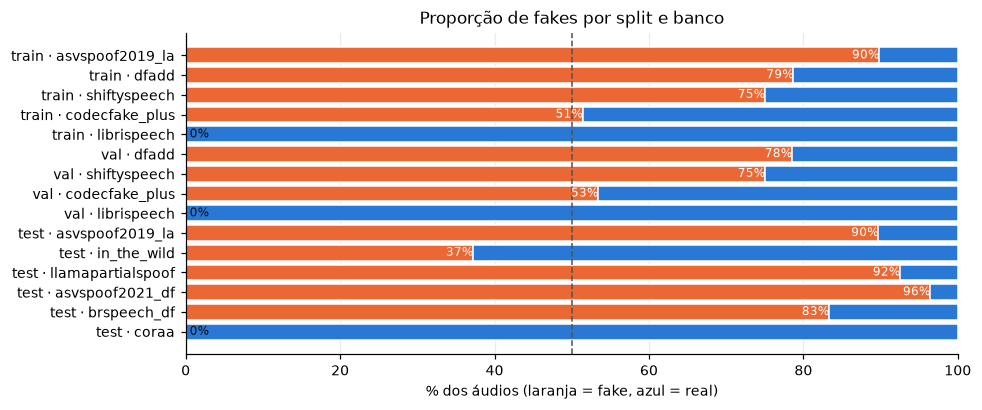

In [15]:
pct = (usado.groupby(["split", "source_dataset"])["label"].agg(["mean", "size"])
       .rename(columns={"mean": "% fake", "size": "áudios"}))
pct["% fake"] = (100 * pct["% fake"]).round(1)
por_split = usado.groupby("split")["label"].mean().mul(100).round(1).reindex(["train", "val", "test"])
print("% de fakes por split:", por_split.to_dict())

fig, ax = plt.subplots(figsize=(9, 3.8))
rot, vals = [], []
for split in ["train", "val", "test"]:
    for src in ORDEM_FONTES:
        if (split, src) in pct.index:
            rot.append(f"{split} · {src}")
            vals.append(pct.loc[(split, src), "% fake"])
y = np.arange(len(rot))
ax.barh(y, vals, color=FAKE_C, edgecolor="white", linewidth=1)
ax.barh(y, [100 - v for v in vals], left=vals, color=REAL_C, edgecolor="white", linewidth=1)
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:.0f}%", va="center", fontsize=8, color="white" if v > 12 else "#0b0b0b",
            ha="right" if v > 12 else "left")
ax.axvline(50, color="#52514e", lw=1, ls="--")
ax.set_yticks(y, rot)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos áudios (laranja = fake, azul = real)")
ax.set_title("Proporção de fakes por split e banco")
plt.tight_layout()
plt.show()

**Conclusão:** o treino é 73,5% fake e a validação 69,3%; o ASVspoof 2019 tem 9 fakes por real, o DFADD quase 4 por 1, e o LibriSpeech só tem reais; por isso o treino usa amostragem 50/50 (seção 6) e a métrica principal é a EER, que não depende dessa proporção.

### 5.2 Composição do pool de treino por fonte

**O que faz:** mostra quanto cada banco representa no split de treino.
**Por quê:** se uma fonte domina, o modelo aprende principalmente os geradores e as condições de gravação dela.

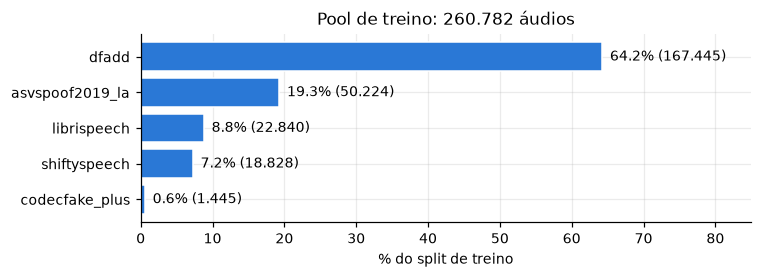

In [16]:
treino = df[df.split == "train"]
comp = treino["source_dataset"].value_counts()
comp_pct = 100 * comp / comp.sum()
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(comp.index[::-1], comp_pct[::-1], color=CAT[0], edgecolor="white", linewidth=1)
for i, (n, p) in enumerate(zip(comp[::-1], comp_pct[::-1])):
    ax.text(p, i, f"  {p:.1f}% ({fmt(n)})", va="center")
ax.set_xlim(0, 85)
ax.set_xlabel("% do split de treino")
ax.set_title(f"Pool de treino: {fmt(len(treino))} áudios")
plt.tight_layout()
plt.show()
DFADD_PCT = comp_pct["dfadd"]

**Conclusão:** o DFADD sozinho é cerca de 64% do pool de treino; sem um teto por fonte, o modelo veria quase só os 5 TTS do DFADD e as gravações do VCTK, o que justifica a amostragem com teto por fonte e por gerador.

**Atalho de fonte.** Além da proporção, cada banco tem um "sotaque" de gravação (microfone, sala, ruído). Isso vira atalho quando uma fonte tem só uma classe: o LibriSpeech (audiolivros) é **só real**, então o modelo poderia aprender "som de audiolivro = real". Os reais do ShiftySpeech também são audiolivros (e lá existem os fakes correspondentes), o que ajuda a quebrar esse atalho. É um risco que fica registrado nas limitações.

### 5.3 A duração separa real de fake?

**O que faz:** para cada banco com as duas classes, calcula a mediana da duração de reais e falsos e a **AUC da duração sozinha** como classificador.
**Por quê:** se só a duração já separa as classes, o modelo pode usar essa pista. A AUC mede isso de forma simples: 0,5 = a duração não ajuda nada; 1,0 = separa perfeitamente (usamos max(AUC, 1 − AUC), porque tanto "fake mais longo" quanto "fake mais curto" são pistas).

> ⚠️ **Fora da trilha (AUC):** a AUC é a área sob a curva ROC, explicada na seção 7. Aqui basta saber que é a chance de um fake sorteado ter um valor maior que um real sorteado.

,banco,papel,mediana real (s),mediana fake (s),AUC da duração
0,asvspoof2019_la,treino/val,3.24,2.94,0.577
1,dfadd,treino/val,3.13,3.82,0.664
2,shiftyspeech,treino/val,5.21,5.21,0.500
3,codecfake_plus,treino/val,5.14,6.10,0.598
4,in_the_wild,teste,2.99,4.05,0.619
5,llamapartialspoof,teste,4.60,5.18,0.540
6,asvspoof2021_df,teste,3.14,2.75,0.583
7,brspeech_df,teste,11.00,11.05,0.519
8,POOL train+val (todos juntos),treino/val,4.00,3.76,0.586


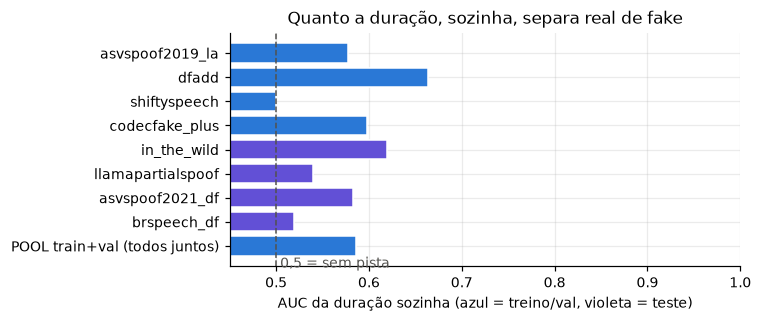

In [17]:
def auc_pista(y, v):
    a = roc_auc_score(y, v)
    return max(a, 1 - a)


linhas = []
for src in ORDEM_FONTES:
    g = usado[usado.source_dataset == src]
    if g.label.nunique() < 2:
        continue
    med = g.groupby("label")["duration_s"].median()
    linhas.append({"banco": src, "papel": "treino/val" if g.split.iloc[0] != "test" else "teste",
                   "mediana real (s)": round(med[0], 2), "mediana fake (s)": round(med[1], 2),
                   "AUC da duração": round(auc_pista(g.label, g.duration_s), 3)})
pool = usado[usado.split.isin(["train", "val"])]
linhas.append({"banco": "POOL train+val (todos juntos)", "papel": "treino/val",
               "mediana real (s)": round(pool[pool.label == 0].duration_s.median(), 2),
               "mediana fake (s)": round(pool[pool.label == 1].duration_s.median(), 2),
               "AUC da duração": round(auc_pista(pool.label, pool.duration_s), 3)})
TAB_DUR = pd.DataFrame(linhas)
display(TAB_DUR)

fig, ax = plt.subplots(figsize=(7, 3))
cores = [CAT[0] if p == "treino/val" else CAT[6] for p in TAB_DUR["papel"]]
ax.barh(TAB_DUR["banco"][::-1], TAB_DUR["AUC da duração"][::-1], color=cores[::-1], edgecolor="white")
ax.axvline(0.5, color="#52514e", ls="--", lw=1)
ax.text(0.5, -0.9, " 0,5 = sem pista", color="#52514e")
ax.set_xlim(0.45, 1)
ax.set_xlabel("AUC da duração sozinha (azul = treino/val, violeta = teste)")
ax.set_title("Quanto a duração, sozinha, separa real de fake")
plt.tight_layout()
plt.show()

**Conclusão:** a duração sozinha dá pistas fracas a moderadas (AUC entre 0,50 e 0,66 por banco, a maior no DFADD, onde os fakes são mais longos); no pool juntando bancos ela pesa mais, por causa do LibriSpeech longo e só real. Duas escolhas reduzem esse atalho: o recorte fixo de 4 s (o modelo nunca vê a duração total) e a repetição do áudio curto em vez de completar com zeros (a quantidade de silêncio não denuncia a duração). Ainda sobra uma pista para áudios com menos de 4 s, que aparecem repetidos.

### 5.4 A taxa de amostragem separa real de fake?

**O que faz:** cruza, em cada banco, a taxa de amostragem original com o label.
**Por quê:** se reais e falsos de um banco têm taxas diferentes, o modelo pode separar as classes só pela banda de frequência, sem ouvir a voz.

In [18]:
TAB_SR = (usado.groupby(["source_dataset", "label"])["sample_rate"]
          .agg(lambda s: ", ".join(f"{int(v) // 1000} kHz" for v in sorted(s.unique())))
          .unstack().rename(columns={0: "real", 1: "fake"}).reindex(ORDEM_FONTES).fillna("—"))
TAB_SR["separa as classes?"] = np.where(
    (TAB_SR["real"] != TAB_SR["fake"]) & (TAB_SR["real"] != "—") & (TAB_SR["fake"] != "—"),
    "⚠️ SIM", "não")
display(TAB_SR)

label,real,fake,separa as classes?
source_dataset,,,
asvspoof2019_la,16 kHz,16 kHz,não
dfadd,16 kHz,16 kHz,não
shiftyspeech,24 kHz,24 kHz,não
codecfake_plus,16 kHz,16 kHz,não
librispeech,16 kHz,—,não
in_the_wild,16 kHz,16 kHz,não
llamapartialspoof,16 kHz,16 kHz,não
asvspoof2021_df,16 kHz,16 kHz,não
brspeech_df,48 kHz,24 kHz,⚠️ SIM


**Conclusão:** só o **BRSpeech-DF** tem esse problema, e de forma perfeita: os 1.320 reais estão em **48 kHz** e os 6.587 fakes em **24 kHz** (embora o card do banco diga que tudo foi reamostrado para 24 kHz). O ShiftySpeech está em 24 kHz nas duas classes, e o resto em 16 kHz.

**Por que reamostrar resolve:** um áudio a 48 kHz pode ter conteúdo até 24 kHz, e um a 24 kHz só até 12 kHz. Se o modelo visse as taxas originais, bastaria olhar se há energia acima de 12 kHz. Ao converter **tudo para 16 kHz** com reamostragem de verdade (que aplica um filtro passa-baixa *anti-aliasing* antes de descartar amostras, como faz `torchaudio.functional.resample`), as duas classes ficam limitadas à mesma faixa de 0 a 8 kHz e a pista desaparece. O gráfico abaixo mostra isso no espectro médio de 30 reais e 30 fakes do BRSpeech-DF.

> ⚠️ **Fora da trilha:** reamostragem e filtro anti-aliasing (processamento de sinais). Sem o filtro, as frequências acima da nova metade da taxa "dobram" para baixo e viram ruído falso (*aliasing*).

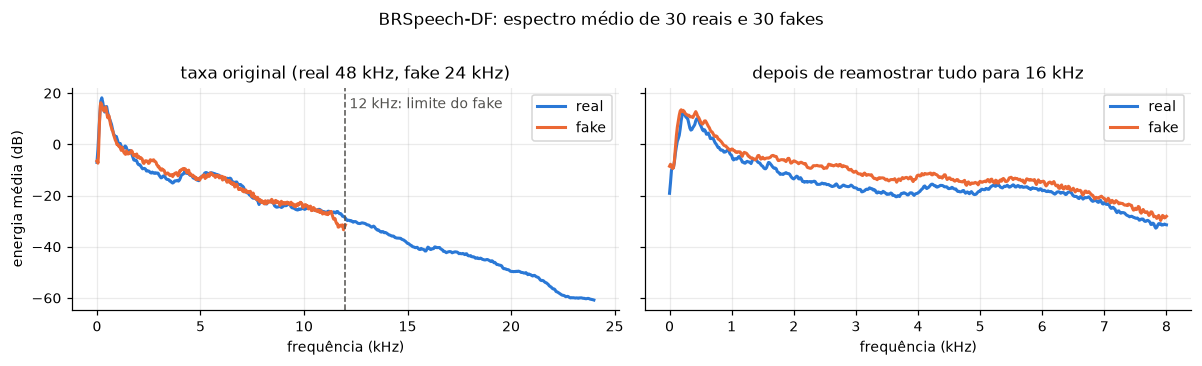

In [19]:
def espectro_medio(rows, resample_to=None, n=30):
    """Espectro médio (dB) de até n áudios: 2 s do meio de cada um."""
    specs, sr_out = [], None
    for row in rows.head(n).itertuples():
        sr = int(row.sample_rate)
        meio = int(row.duration_s * sr) // 2
        x, sr = sf.read(row.path, start=max(0, meio - sr), frames=2 * sr, dtype="float32", always_2d=True)
        x = torch.from_numpy(x.mean(axis=1))
        if resample_to:
            x, sr = AF.resample(x, sr, resample_to), resample_to
        p = torch.stft(x, n_fft=1024, hop_length=256, window=torch.hann_window(1024),
                       return_complex=True).abs().pow(2).mean(dim=1)
        specs.append(10 * torch.log10(p + 1e-10).numpy())
        sr_out = sr
    return np.linspace(0, sr_out / 2, len(specs[0])), np.mean(specs, axis=0)


br = usado[(usado.source_dataset == "brspeech_df") & (usado.duration_s > 3)].sample(frac=1, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, rs, titulo in [(axes[0], None, "taxa original (real 48 kHz, fake 24 kHz)"),
                       (axes[1], SAMPLE_RATE, "depois de reamostrar tudo para 16 kHz")]:
    for lab, cor, nome in [(0, REAL_C, "real"), (1, FAKE_C, "fake")]:
        f, s = espectro_medio(br[br.label == lab], rs)
        ax.plot(f / 1000, s, color=cor, lw=2, label=nome)
    ax.set_title(titulo)
    ax.set_xlabel("frequência (kHz)")
    ax.legend()
axes[0].axvline(12, color="#52514e", ls="--", lw=1)
axes[0].text(12, axes[0].get_ylim()[1] - 8, " 12 kHz: limite do fake", color="#52514e")
axes[0].set_ylabel("energia média (dB)")
plt.suptitle("BRSpeech-DF: espectro médio de 30 reais e 30 fakes", y=1.02)
plt.tight_layout()
plt.show()

**Conclusão:** na taxa original, os reais têm energia acima de 12 kHz e os fakes não, uma pista trivial; depois de reamostrar para 16 kHz, as duas curvas vão até 8 kHz e essa diferença some. Fica a dúvida (registrada no `audit_report.md`) se ainda há diferenças de banda **abaixo** de 8 kHz por causa de como cada classe foi produzida; por isso desconfiamos de um resultado bom demais nesse banco.

### 5.5 O volume separa real de fake?

**O que faz:** lê `EDA_PER_CLASS` áudios por classe em cada banco (trecho central de 4 s) e calcula o volume (RMS, em dB) e a AUC do volume sozinho.
**Por quê:** se os fakes de um banco são sistematicamente mais altos ou mais baixos, o volume vira atalho.

,banco,RMS real (dB),RMS fake (dB),AUC do volume
0,asvspoof2019_la,-19.299999,-17.700001,0.678
1,dfadd,-25.700001,-22.600000,0.744
2,shiftyspeech,-24.799999,-24.900000,0.510
3,codecfake_plus,-24.400000,-25.000000,0.527
4,librispeech,-25.000000,NaN,NaN
5,in_the_wild,-25.400000,-28.600000,0.676
6,llamapartialspoof,-23.100000,-23.100000,0.504
7,asvspoof2021_df,-18.500000,-17.200001,0.639
8,brspeech_df,-25.700001,-24.100000,0.619
9,coraa,-26.799999,NaN,NaN


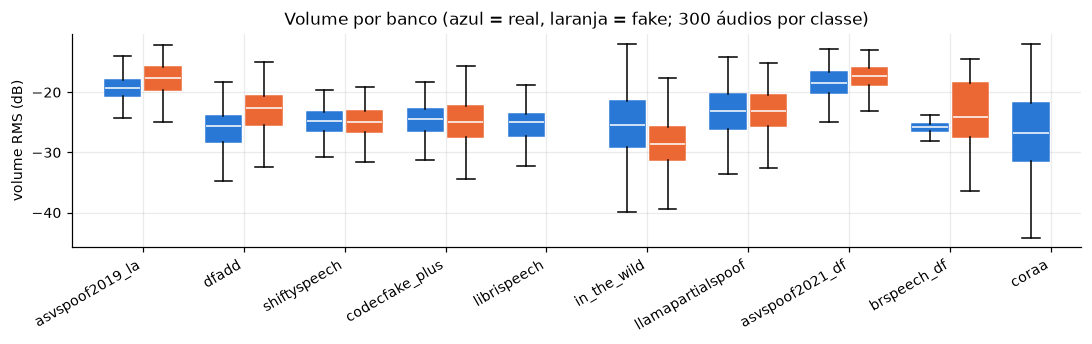

In [20]:
amostra_vol = pd.concat([g.sample(min(len(g), EDA_PER_CLASS), random_state=SEED)
                         for _, g in usado.groupby(["source_dataset", "label"])])
ds_vol = AudioDataset(amostra_vol.path, amostra_vol.label, amostra_vol.sample_rate, amostra_vol.duration_s,
                      crop_s=CROP_S, target_sr=SAMPLE_RATE, mode="center")
rms = []
for x, _ in DataLoader(ds_vol, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS):
    rms.append(20 * torch.log10(x.pow(2).mean(dim=1).sqrt() + 1e-8))
amostra_vol = amostra_vol.assign(rms_db=torch.cat(rms).numpy())

linhas = []
for src in ORDEM_FONTES:
    g = amostra_vol[amostra_vol.source_dataset == src]
    med = g.groupby("label")["rms_db"].median()
    linhas.append({"banco": src,
                   "RMS real (dB)": round(med.get(0, np.nan), 1), "RMS fake (dB)": round(med.get(1, np.nan), 1),
                   "AUC do volume": round(auc_pista(g.label, g.rms_db), 3) if g.label.nunique() == 2 else np.nan})
TAB_VOL = pd.DataFrame(linhas)
display(TAB_VOL)

fig, ax = plt.subplots(figsize=(10, 3.2))
pos = np.arange(len(ORDEM_FONTES))
for lab, cor, desl in [(0, REAL_C, -0.2), (1, FAKE_C, 0.2)]:
    dados = [amostra_vol[(amostra_vol.source_dataset == s) & (amostra_vol.label == lab)].rms_db.values
             for s in ORDEM_FONTES]
    ok = [i for i, d in enumerate(dados) if len(d)]
    bp = ax.boxplot([dados[i] for i in ok], positions=pos[ok] + desl, widths=0.35, patch_artist=True,
                    showfliers=False, medianprops={"color": "white"})
    for b in bp["boxes"]:
        b.set(facecolor=cor, edgecolor=cor)
ax.set_xticks(pos, ORDEM_FONTES, rotation=30, ha="right")
ax.set_ylabel("volume RMS (dB)")
ax.set_title(f"Volume por banco (azul = real, laranja = fake; {EDA_PER_CLASS} áudios por classe)")
plt.tight_layout()
plt.show()

**Conclusão:** o volume dá pista em vários bancos (AUC 0,68 no ASVspoof 2019 e 0,74 no DFADD, onde os fakes são cerca de 3 dB mais altos; no In-the-Wild os fakes são cerca de 3 dB mais baixos), então seria um atalho de verdade. A padronização de cada log-mel (seção 6.2) remove o ganho global do áudio e, com ele, essa pista; ela não remove diferenças de dinâmica *dentro* do áudio.

### 5.6 Proporções nos bancos de teste

**O que faz:** mostra quantos reais e falsos há em cada banco de teste.
**Por quê:** a proporção muda o significado da acurácia e da precisão; um banco com 96% de fakes dá 96% de acurácia a quem chuta sempre "fake".

In [21]:
TESTES = ["in_the_wild", "llamapartialspoof", "brspeech_df", "asvspoof2019_la", "asvspoof2021_df", "coraa"]
TIPO = {"in_the_wild": "principal", "llamapartialspoof": "principal", "brspeech_df": "principal (pt)",
        "asvspoof2019_la": "secundário", "asvspoof2021_df": "secundário", "coraa": "falso alarme pt-BR"}
teste_full = df[df.split == "test"]
TAB_TESTE = teste_full.groupby("source_dataset")["label"].agg(
    áudios="size", real=lambda s: int((s == 0).sum()), fake=lambda s: int((s == 1).sum())).reindex(TESTES)
TAB_TESTE["% fake"] = (100 * TAB_TESTE["fake"] / TAB_TESTE["áudios"]).round(1)
TAB_TESTE["acurácia de 'sempre fake'"] = TAB_TESTE["% fake"].map(lambda v: f"{v:.1f}%")
TAB_TESTE.insert(0, "tipo", [TIPO[s] for s in TESTES])
display(TAB_TESTE)

,tipo,áudios,real,fake,% fake,acurácia de 'sempre fake'
source_dataset,,,,,,
in_the_wild,principal,31779,19963,11816,37.2,37.2%
llamapartialspoof,principal,140616,10573,130043,92.5,92.5%
brspeech_df,principal (pt),7907,1320,6587,83.3,83.3%
asvspoof2019_la,secundário,71237,7355,63882,89.7,89.7%
asvspoof2021_df,secundário,152955,5535,147420,96.4,96.4%
coraa,falso alarme pt-BR,12350,12350,0,0.0,0.0%


**Conclusão:** os bancos de teste vão de 0% de fakes (CORAA) a 96% (ASVspoof 2021 DF); só o In-the-Wild tem mais reais que fakes (37% fake). Por isso, além de usar amostras com teto por classe (seção 7), olhamos AUC e EER, que não dependem da proporção.

## 6. Treinamento do baseline

### 6.1 Amostragem balanceada, sorteada de novo a cada época

**A regra:**

1. A cada época sorteamos `PER_CLASS_PER_EPOCH` áudios **reais** e o mesmo número de áudios **falsos** do split de treino (50/50).
2. **Teto por fonte:** dentro de cada classe, as fontes recebem fatias iguais. Se uma fonte não tem áudios suficientes para a sua fatia (como o CodecFake+), ela entra inteira e a sobra é dividida igualmente entre as outras. Assim, o DFADD (64% do pool) vale tanto quanto o ShiftySpeech.
3. **Teto por gerador:** dentro de cada fonte, a fatia é dividida igualmente entre os geradores, com a mesma redistribuição. Assim, nenhum dos 6 geradores antigos do ASVspoof 2019 (A01–A06) nem dos 5 TTS do DFADD domina.
4. **Sorteio sem repetição entre épocas:** cada grupo (classe, fonte, gerador) tem uma fila embaralhada; cada época pega os próximos áudios da fila, e a fila só é reembaralhada quando acaba. Assim, ao longo das épocas o modelo passa pela **maior parte do pool**, e não sempre pelos mesmos áudios.

**Por quê:** o pool de treino é 73,5% fake, e o DFADD sozinho é cerca de 64% dele. Sem a regra, o modelo aprenderia sobretudo "o que é o DFADD". Com ela, cada época é balanceada e diversa.

> ⚠️ **Fora da trilha:** a Aula 3 mostra o problema do desbalanceamento (acurácia enganosa), mas não ensina como tratar. A amostragem balanceada por grupo é a técnica que escolhemos; a alternativa com pesos de classe está discutida na tabela de decisões (3.7).

**O que faz o código:** monta os grupos, calcula as cotas de cada grupo por época e mostra a composição de uma época.

In [22]:
pool_tr = df[df.split == "train"].reset_index(drop=True)
pool_tr["gen_key"] = pool_tr["generator"].fillna("(real)")
GRUPOS = {k: np.asarray(v) for k, v in pool_tr.groupby(["label", "source_dataset", "gen_key"]).indices.items()}


def dividir_igual(total, tamanhos):
    """Divide `total` igualmente entre os grupos, sem passar do tamanho de cada um; a sobra vai para os outros."""
    cotas = {k: 0 for k in tamanhos}
    ativos = [k for k, n in tamanhos.items() if n > 0]
    resta = total
    while resta > 0 and ativos:
        fatia = max(resta // len(ativos), 1)
        prox = []
        for k in ativos:
            dar = min(fatia, tamanhos[k] - cotas[k], resta)
            cotas[k] += dar
            resta -= dar
            if cotas[k] < tamanhos[k]:
                prox.append(k)
            if resta == 0:
                break
        ativos = prox
    return cotas


COTAS = {}
for lab in (0, 1):
    fontes = {s: sum(len(v) for (l, s2, g), v in GRUPOS.items() if l == lab and s2 == s)
              for s in pool_tr.loc[pool_tr.label == lab, "source_dataset"].unique()}
    for src, cota_src in dividir_igual(PER_CLASS_PER_EPOCH, fontes).items():
        gens = {g: len(v) for (l, s2, g), v in GRUPOS.items() if l == lab and s2 == src}
        for g, c in dividir_igual(cota_src, gens).items():
            COTAS[(lab, src, g)] = c

TAB_COTAS = pd.DataFrame([{"classe": "real" if l == 0 else "fake", "fonte": s, "gerador": g,
                           "no pool": len(GRUPOS[(l, s, g)]), "por época": c}
                          for (l, s, g), c in COTAS.items()])
resumo = TAB_COTAS.groupby(["classe", "fonte"])[["no pool", "por época"]].sum()
resumo["% da classe na época"] = (100 * resumo["por época"] / PER_CLASS_PER_EPOCH).round(1)
resumo["% da classe no pool"] = (100 * resumo["no pool"]
                                 / resumo.groupby(level=0)["no pool"].transform("sum")).round(1)
display(resumo)
print(f"Cada época: {fmt(TAB_COTAS['por época'].sum())} áudios "
      f"({fmt(PER_CLASS_PER_EPOCH)} reais + {fmt(PER_CLASS_PER_EPOCH)} falsos), "
      f"{math.floor(TAB_COTAS['por época'].sum() / BATCH_SIZE)} iterações de {BATCH_SIZE}.")

no pool  por época  % da classe na época  \
classe fonte                                                       
fake   asvspoof2019_la    45096       8086                  32.3   
       codecfake_plus       743        743                   3.0   
       dfadd             131700       8086                  32.3   
       shiftyspeech       14121       8085                  32.3   
real   asvspoof2019_la     5128       5128                  20.5   
       codecfake_plus       702        702                   2.8   
       dfadd              35745       7232                  28.9   
       librispeech        22840       7231                  28.9   
       shiftyspeech        4707       4707                  18.8   

                        % da classe no pool  
classe fonte                                 
fake   asvspoof2019_la                 23.5  
       codecfake_plus                   0.4  
       dfadd                           68.7  
       shiftyspeech                     7.4  
real   asvspoof2019_la                  7.4  
       codecfake_plus                   1.0  
       dfadd                           51.7  
       librispeech                     33.0  
       shiftyspeech                     6.8

Cada época: 50.000 áudios (25.000 reais + 25.000 falsos), 781 iterações de 64.


**Conclusão:** em cada época, as fontes ficam com fatias parecidas dentro de cada classe (o CodecFake+ entra com tudo o que tem), em vez de o DFADD dominar como no pool.

**O sorteador por época** (fila embaralhada por grupo) e o `Sampler`, que entrega ao `DataLoader` a lista de índices da época:

In [23]:
class SorteadorPorEpoca:
    """Cada grupo tem uma fila embaralhada; cada época consome os próximos itens dela."""

    def __init__(self, grupos, seed):
        self.rng = np.random.default_rng(seed)
        self.filas = {k: self.rng.permutation(v) for k, v in grupos.items()}
        self.pos = {k: 0 for k in grupos}

    def tirar(self, k, n):
        saida = []
        while n > 0:
            fila, p = self.filas[k], self.pos[k]
            pega = min(n, len(fila) - p)
            saida.append(fila[p:p + pega])
            p, n = p + pega, n - pega
            if p == len(fila):                      # fila acabou: reembaralha e recomeça
                self.filas[k], p = self.rng.permutation(fila), 0
            self.pos[k] = p
        return np.concatenate(saida)

    def epoca(self, cotas):
        idx = np.concatenate([self.tirar(k, c) for k, c in cotas.items() if c > 0])
        return self.rng.permutation(idx)            # embaralha a época (Aula 6)


class IndicesDaEpoca(Sampler):
    """Entrega ao DataLoader os índices sorteados para a época atual."""

    def __init__(self):
        self.indices = np.array([], dtype=int)

    def __iter__(self):
        return iter(self.indices.tolist())

    def __len__(self):
        return len(self.indices)

### 6.2 Pipeline de áudio

`áudio → mono → 16 kHz (reamostrando SEMPRE que a taxa original for outra) → recorte de 4 s → log-mel espectrograma → padronização → CNN`

- **Leitura e recorte** (classe `AudioDataset`, em `src/dataset.py`): lê só o trecho necessário do arquivo, converte para mono e reamostra para 16 kHz com `torchaudio.functional.resample` (que tem o filtro anti-aliasing). No treino o trecho de 4 s é **aleatório** (cada época vê um pedaço diferente do mesmo áudio); na validação e no teste é o **central** (sempre o mesmo, para o resultado ser comparável). Áudio com menos de 4 s é **repetido** até completar.
- **Log-mel na GPU:** o espectrograma é calculado em lote na GPU, que é muito mais rápida que a CPU para isso.
- **Padronização por exemplo:** cada espectrograma fica com média 0 e desvio 1. Como um ganho de volume vira uma constante somada ao log-mel, isso remove o volume como pista (seção 5.5). É a mesma ideia da escala dos pixels da Aula 6, aplicada a cada exemplo.

> ⚠️ **Fora da trilha:** a classe `Dataset` do PyTorch (a trilha usa o `DataLoader` com dados prontos, como o MNIST), a leitura de áudio com `soundfile` e o `miniaudio` como plano B. Cerca de 40% dos FLAC do ASVspoof 2021 DF dão erro no decodificador do `soundfile` ("unknown error in flac decoder"); o `miniaudio` lê esses arquivos e devolve exatamente as mesmas amostras nos arquivos que os dois conseguem ler.

**O que faz o código:** cria os `DataLoader`s de treino e validação e a função que transforma um lote de ondas em log-mels.

In [24]:
val_df = df[df.split == "val"]
if VAL_MAX:
    val_df = val_df.sample(VAL_MAX, random_state=SEED)
val_df = val_df.reset_index(drop=True)

train_ds = AudioDataset(pool_tr.path, pool_tr.label, pool_tr.sample_rate, pool_tr.duration_s,
                        crop_s=CROP_S, target_sr=SAMPLE_RATE, mode="random")
val_ds = AudioDataset(val_df.path, val_df.label, val_df.sample_rate, val_df.duration_s,
                      crop_s=CROP_S, target_sr=SAMPLE_RATE, mode="center")
sampler = IndicesDaEpoca()
g_loader = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS,
                          pin_memory=True, persistent_workers=True, drop_last=True, generator=g_loader)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=True, persistent_workers=True)

mel_gpu = torchaudio.transforms.MelSpectrogram(sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=WIN_LENGTH,
                                               hop_length=HOP_LENGTH, n_mels=N_MELS).to(DEVICE)


def para_logmel(ondas):
    """(lote, amostras) -> (lote, 1, n_mels, quadros), padronizado por exemplo."""
    m = torch.log(mel_gpu(ondas) + 1e-6)
    m = (m - m.mean(dim=(1, 2), keepdim=True)) / (m.std(dim=(1, 2), keepdim=True) + 1e-5)
    return m.unsqueeze(1)


N_FRAMES = int(CROP_S * SAMPLE_RATE) // HOP_LENGTH + 1
print(f"treino: pool de {fmt(len(train_ds))} áudios | validação: {fmt(len(val_ds))} áudios "
      f"({(val_df.label == 1).mean():.1%} fake)")
print(f"entrada da CNN: 1 × {N_MELS} × {N_FRAMES}")

treino: pool de 260.782 áudios | validação: 51.189 áudios (69.3% fake)
entrada da CNN: 1 × 64 × 401


### 6.3 A CNN

Arquitetura no padrão da Aula 10 (conv → pool repetido, filtros crescendo, achatar, camada densa de saída):

- **4 blocos** `Conv 3×3 (padding 1) → BatchNorm → ReLU → MaxPool 2×2`, com 16, 32, 64 e 128 filtros. Quatro blocos reduzem 64 × 401 para 4 × 25, o bastante para cada neurônio do último bloco "enxergar" um pedaço grande do espectrograma (campo receptivo, Aula 9).
- **Flatten → Dropout 0,3 → Linear com 1 saída** (o *logit*; a sigmoide da Aula 3 transforma em probabilidade de ser fake).
- Cerca de 110 mil parâmetros: pequena de propósito, porque é o baseline e treina em minutos.

> ⚠️ **Fora da trilha (BatchNorm):** normaliza a saída de cada filtro dentro do lote (média 0, desvio 1, com uma escala e um deslocamento aprendidos). Deixa o treino mais estável e menos sensível à taxa de aprendizado.

**Perda e otimizador:**
- **`BCEWithLogitsLoss`**: a entropia cruzada binária da Aula 3, com a sigmoide já embutida (é mais estável numericamente do que aplicar a sigmoide e depois a perda). ⚠️ **Fora da trilha** só o nome da função do PyTorch; a ideia é a da aula.
- **Adam** com taxa de 0,001 (Aula 6).

In [25]:
class CNNPequena(nn.Module):
    def __init__(self, n_mels, n_frames, dropout):
        super().__init__()
        camadas, c_in = [], 1
        for c_out in (16, 32, 64, 128):
            camadas += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.BatchNorm2d(c_out),
                        nn.ReLU(), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*camadas)
        n_flat = 128 * (n_mels // 16) * (n_frames // 16)
        self.saida = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(n_flat, 1))

    def forward(self, x):
        return self.saida(self.features(x)).squeeze(1)    # logit (sem sigmoide)


torch.manual_seed(SEED)
model = CNNPequena(N_MELS, N_FRAMES, DROPOUT).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
print(model)
print(f"parâmetros treináveis: {fmt(sum(p.numel() for p in model.parameters() if p.requires_grad))}")

CNNPequena(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=

### 6.4 Métricas usadas na validação e loop de treino

**O que faz:** define a EER e roda o loop de treino da Aula 6 (forward, perda, `zero_grad`, `backward`, `step`). Ao fim de cada época, avalia a validação inteira e guarda o checkpoint **só quando a EER melhora**; se a EER passar `PATIENCE` épocas sem melhorar, para (early stopping da Aula 7, com "guardar os melhores pesos").

**Por que a EER, e não a acurácia, escolhe o checkpoint:** a acurácia depende da proporção real/fake (a validação é 69% fake) e de um limiar fixo de 0,5. A **EER** (*Equal Error Rate*) é o ponto em que a taxa de falsos alarmes (real acusado de fake) é igual à taxa de fakes que escapam; não depende da proporção nem de escolher um limiar antes. Quanto menor, melhor (0% = perfeito, 50% = chute).

> ⚠️ **Fora da trilha:** EER e curva ROC (explicadas em detalhe na seção 7). Usamos `roc_curve` do `scikit-learn` para calculá-las.

O checkpoint vai para `models/` (que está no `.gitignore`).

In [26]:
def eer_e_limiar(y, p):
    """EER e o limiar (em probabilidade) em que os dois erros se igualam."""
    fpr, tpr, thr = roc_curve(y, p)
    fnr = 1 - tpr
    i = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[i] + fnr[i]) / 2), float(min(thr[i], 1.0))


@torch.no_grad()
def prever(loader):
    """Probabilidade de fake para cada áudio do loader (na ordem), rótulos e perda média."""
    model.eval()
    ys, ps, perda, n = [], [], 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        logit = model(para_logmel(x))
        perda += criterion(logit, y).item() * len(y)
        n += len(y)
        ys.append(y.cpu())
        ps.append(torch.sigmoid(logit).cpu())
    return torch.cat(ys).numpy().astype(int), torch.cat(ps).numpy(), perda / n


sorteador = SorteadorPorEpoca(GRUPOS, SEED)
vistos = np.zeros(len(pool_tr), dtype=bool)
historico, melhor_eer, sem_melhora = [], float("inf"), 0
t_inicio = time.time()

for epoca in range(1, MAX_EPOCHS + 1):
    t0 = time.time()
    sampler.indices = sorteador.epoca(COTAS)
    vistos[sampler.indices] = True

    model.train()
    soma, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        perda = criterion(model(para_logmel(x)), y)
        optimizer.zero_grad()
        perda.backward()
        optimizer.step()
        soma += perda.item() * len(y)
        n += len(y)

    y_val, p_val, perda_val = prever(val_loader)
    eer, limiar = eer_e_limiar(y_val, p_val)
    reg = {"época": epoca, "perda treino": soma / n, "perda val": perda_val, "EER val": eer,
           "AUC val": roc_auc_score(y_val, p_val), "acurácia val (0,5)": accuracy_score(y_val, p_val >= 0.5),
           "% do pool já visto": 100 * vistos.mean(), "segundos": time.time() - t0}
    historico.append(reg)

    marca = ""
    if eer < melhor_eer:
        melhor_eer, sem_melhora, marca = eer, 0, "  <- melhor, checkpoint salvo"
        torch.save({"model_state": model.state_dict(), "epoca": epoca, "eer_val": eer, "limiar_eer_val": limiar,
                    "config": {"N_MELS": N_MELS, "N_FRAMES": N_FRAMES, "DROPOUT": DROPOUT, "SAMPLE_RATE": SAMPLE_RATE,
                               "CROP_S": CROP_S, "N_FFT": N_FFT, "WIN_LENGTH": WIN_LENGTH,
                               "HOP_LENGTH": HOP_LENGTH}}, CKPT_PATH)
    else:
        sem_melhora += 1
    print(f"época {epoca:2d} | perda treino {reg['perda treino']:.4f} | perda val {perda_val:.4f} | "
          f"EER val {100 * eer:5.2f}% | AUC val {reg['AUC val']:.4f} | visto {reg['% do pool já visto']:5.1f}% | "
          f"{reg['segundos']:.0f} s{marca}")
    if sem_melhora >= PATIENCE:
        print(f"early stopping: {PATIENCE} épocas sem melhorar a EER da validação")
        break

HIST = pd.DataFrame(historico)
print(f"\ntempo total de treino: {(time.time() - t_inicio) / 60:.1f} min | melhor EER val: {100 * melhor_eer:.2f}%")

época  1 | perda treino 0.3620 | perda val 0.1604 | EER val  6.44% | AUC val 0.9864 | visto  19.2% | 100 s  <- melhor, checkpoint salvo


época  2 | perda treino 0.2062 | perda val 0.2249 | EER val  2.99% | AUC val 0.9952 | visto  33.2% | 46 s  <- melhor, checkpoint salvo


época  3 | perda treino 0.1659 | perda val 0.0809 | EER val  2.82% | AUC val 0.9955 | visto  45.0% | 47 s  <- melhor, checkpoint salvo


época  4 | perda treino 0.1346 | perda val 0.4216 | EER val  4.72% | AUC val 0.9908 | visto  54.4% | 48 s


época  5 | perda treino 0.1179 | perda val 0.0989 | EER val  2.07% | AUC val 0.9961 | visto  63.2% | 74 s  <- melhor, checkpoint salvo


época  6 | perda treino 0.1035 | perda val 0.0974 | EER val  2.44% | AUC val 0.9965 | visto  68.1% | 70 s


... (11 outputs left out)

época 18 | perda treino 0.0408 | perda val 0.1084 | EER val  1.32% | AUC val 0.9981 | visto 100.0% | 70 s


época 19 | perda treino 0.0372 | perda val 0.0988 | EER val  1.35% | AUC val 0.9984 | visto 100.0% | 74 s


época 20 | perda treino 0.0359 | perda val 0.1859 | EER val  1.76% | AUC val 0.9980 | visto 100.0% | 73 s


época 21 | perda treino 0.0379 | perda val 0.0650 | EER val  1.92% | AUC val 0.9977 | visto 100.0% | 74 s
early stopping: 5 épocas sem melhorar a EER da validação

tempo total de treino: 23.9 min | melhor EER val: 1.29%


### 6.5 Curvas de treino e cobertura do pool

**O que faz:** mostra a perda de treino e validação e a EER da validação por época, e conta quantos áudios distintos do pool o modelo viu.
**Por quê:** as curvas mostram se houve overfitting (perda de validação subindo enquanto a de treino desce, Aula 7); a cobertura confirma que o sorteio por época passou pela maior parte do pool.

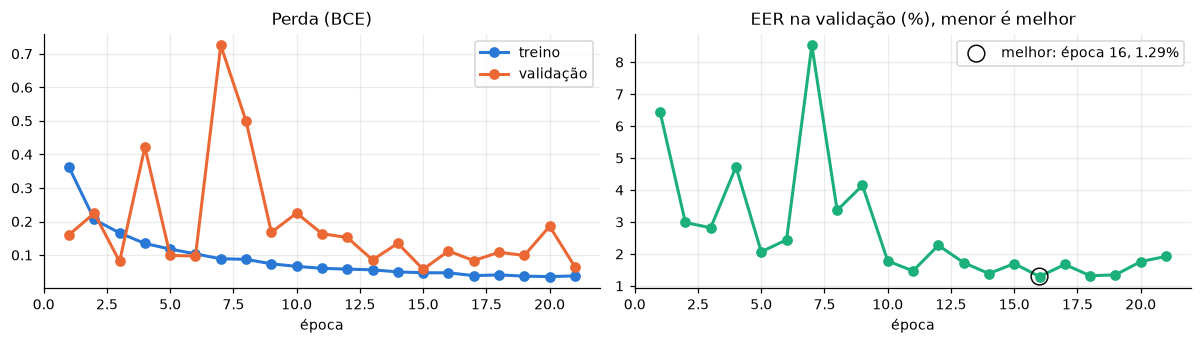

vistos  no pool  % visto
source_dataset  label                          
asvspoof2019_la 0        5128     5128    100.0
                1       45096    45096    100.0
codecfake_plus  0         702      702    100.0
                1         743      743    100.0
dfadd           0       35745    35745    100.0
                1      131700   131700    100.0
librispeech     0       22840    22840    100.0
shiftyspeech    0        4707     4707    100.0
                1       14121    14121    100.0

Áudios distintos vistos no treino: 260.782 de 260.782 (100.0% do pool), em 21 épocas.


In [27]:
melhor = HIST.loc[HIST["EER val"].idxmin()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(HIST["época"], HIST["perda treino"], "o-", color=CAT[0], lw=2, label="treino")
axes[0].plot(HIST["época"], HIST["perda val"], "o-", color=CAT[1], lw=2, label="validação")
axes[0].set_title("Perda (BCE)")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(HIST["época"], 100 * HIST["EER val"], "o-", color=CAT[2], lw=2)
axes[1].scatter([melhor["época"]], [100 * melhor["EER val"]], s=120, facecolors="none", edgecolors="#0b0b0b",
                zorder=3, label=f"melhor: época {int(melhor['época'])}, {100 * melhor['EER val']:.2f}%")
axes[1].set_title("EER na validação (%), menor é melhor")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

cob = (pool_tr.assign(visto=vistos).groupby(["source_dataset", "label"])["visto"]
       .agg(["sum", "size"]).rename(columns={"sum": "vistos", "size": "no pool"}))
cob["% visto"] = (100 * cob["vistos"] / cob["no pool"]).round(1)
display(cob)
print(f"Áudios distintos vistos no treino: {fmt(vistos.sum())} de {fmt(len(pool_tr))} "
      f"({100 * vistos.mean():.1f}% do pool), em {len(HIST)} épocas.")

**Conclusão:** a perda de treino caiu de forma contínua (0,36 → 0,04) e a EER da validação chegou a **1,29% na época 16**; o early stopping parou na época 21 (~24 min). A perda de validação oscila muito (de 0,06 a 0,73) mesmo quando a EER está estável: as probabilidades do modelo são mal calibradas, embora a ordenação (quem é mais "fake") esteja boa. É justamente o caso em que escolher pela EER, e não pela perda ou pela acurácia, faz diferença.

**Cobertura:** o sorteio por época passou por **100% do pool (260.782 áudios distintos)** em 21 épocas. Os grupos pequenos entram inteiros em toda época (os reais do ASVspoof e do ShiftySpeech e todo o CodecFake+, ou seja, foram vistos 21 vezes); os fakes do DFADD foram vistos cerca de 1,3 vez cada, e os do ASVspoof 2019 cerca de 3,8 vezes. Repetir tanto os grupos pequenos é o preço do teto por fonte e pode levar o modelo a decorar esses áudios.

**Sem augmentation nesta versão.** De propósito: o baseline mede o modelo puro. A augmentation (compressão de codec, ruído, reverberação, mudança de ganho) entra na próxima etapa, e só assim dá para saber quanto ela ajuda.

## 7. Avaliação

**Ordem:** primeiro a validação; depois **cada banco de teste separadamente, uma única vez**, com o checkpoint escolhido pela EER da validação e o modelo congelado. Nada do que se vê aqui volta para o treino.

### 7.1 As métricas, em uma frase cada

Nas definições, "positivo" = fake.

| métrica | o que diz | na trilha? |
|:--|:--|:--|
| **Acurácia** | % de áudios classificados certo | sim (Aula 3) |
| **Precisão** | dos áudios acusados de fake, quantos eram mesmo fake | sim (Aula 3) |
| **Recall da classe fake** | dos fakes, quantos o modelo pegou (o resto escapou) | sim (Aula 3) |
| **F1** | média harmônica de precisão e recall: só é alto se os dois forem | citado (Aula 3) |
| **Matriz de confusão** | as 4 contagens: real→real, real→fake (falso alarme), fake→real (escapou), fake→fake | sim (Aula 3) |
| **Taxa de falso alarme** | % de vozes reais acusadas de fake | sim (é 1 − especificidade, da matriz de confusão) |
| **Curva ROC** | para cada limiar, a taxa de falsos alarmes (x) contra a taxa de fakes pegos (y) | ⚠️ fora |
| **AUC-ROC** | área sob a curva ROC: a chance de um fake sorteado receber nota maior que um real sorteado (0,5 = chute, 1 = perfeito) | ⚠️ fora |
| **EER** | o erro no limiar em que falsos alarmes e fakes que escapam são iguais (0% = perfeito, 50% = chute) | ⚠️ fora |

**Por que a acurácia sozinha engana aqui:** a Aula 3 mostra o exemplo da fraude com 1% de casos: quem chuta "não é fraude" acerta 99%. Aqui é o contrário: no ASVspoof 2021 DF, 96% dos áudios são fake, e quem chuta sempre "fake" tem 96% de acurácia sem detectar nada. A precisão também muda com a proporção. AUC e EER olham as duas classes separadamente e por isso **não dependem da proporção**, o que permite comparar bancos diferentes.

**Limiar de decisão.** Acurácia, precisão, recall, F1 e matriz de confusão precisam de um limiar (a Aula 3 usa 0,5). Usamos o **limiar da EER na validação**, escolhido na validação e fixado antes de olhar o teste. Ele equilibra os dois tipos de erro na validação. Como o treino é 50/50, esperávamos algo perto de 0,5, mas ele ficou em **0,039**: o modelo dá notas muito baixas aos reais da validação (ver a conclusão da 7.3).

**Tamanho das amostras de teste:** até `TEST_MAX_PER_CLASS` áudios de cada classe por banco (todos, se houver menos). Isso deixa as classes mais equilibradas que no banco original, então acurácia e precisão da tabela valem para a amostra; AUC e EER valem para o banco.

### 7.2 Funções de avaliação

**O que faz:** calcula todas as métricas para um conjunto de rótulos e probabilidades, deixando em branco as que não fazem sentido quando só há uma classe.
**Por quê:** a mesma função vale para a validação e para cada teste, então os números são comparáveis.

In [28]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
LIMIAR = ckpt["limiar_eer_val"]
print(f"checkpoint: época {ckpt['epoca']}, EER val {100 * ckpt['eer_val']:.2f}%, limiar fixado em {LIMIAR:.3f}")


def metricas(y, p, limiar=LIMIAR):
    pred = (p >= limiar).astype(int)
    n_real, n_fake = int((y == 0).sum()), int((y == 1).sum())
    duas = n_real > 0 and n_fake > 0
    r = {"n amostra": len(y), "n real": n_real, "n fake": n_fake,
         "acurácia": accuracy_score(y, pred),
         "precisão": precision_score(y, pred, zero_division=0) if n_fake else np.nan,
         "recall fake": recall_score(y, pred, zero_division=0) if n_fake else np.nan,
         "F1": f1_score(y, pred, zero_division=0) if n_fake else np.nan,
         "AUC": roc_auc_score(y, p) if duas else np.nan,
         "EER": eer_e_limiar(y, p)[0] if duas else np.nan,
         "falso alarme": ((pred == 1) & (y == 0)).sum() / n_real if n_real else np.nan}
    return r


def desenhar_confusao(ax, y, p, titulo, limiar=LIMIAR):
    cm = confusion_matrix(y, (p >= limiar).astype(int), labels=[0, 1])
    lin = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(lin, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{fmt(cm[i, j])}\n({100 * lin[i, j]:.0f}%)", ha="center", va="center",
                    color="white" if lin[i, j] > 0.6 else "#0b0b0b", fontsize=8)
    ax.set_xticks([0, 1], ["prev. real", "prev. fake"])
    ax.set_yticks([0, 1], ["real", "fake"])
    ax.set_title(titulo, fontsize=9)
    ax.grid(False)

checkpoint: época 16, EER val 1.29%, limiar fixado em 0.039


### 7.3 Validação

**O que faz:** avalia o checkpoint escolhido na validação inteira, com matriz de confusão e curva ROC.
**Por quê:** é o resultado "em casa" (mesmos bancos do treino, locutores diferentes); serve de referência para ver quanto o modelo perde nos testes.

,n amostra,n real,n fake,acurácia,precisão,recall fake,F1,AUC,EER,falso alarme
validação,51189,15730,35459,0.987068,0.994233,0.987055,0.990631,0.998206,0.012925,0.012905


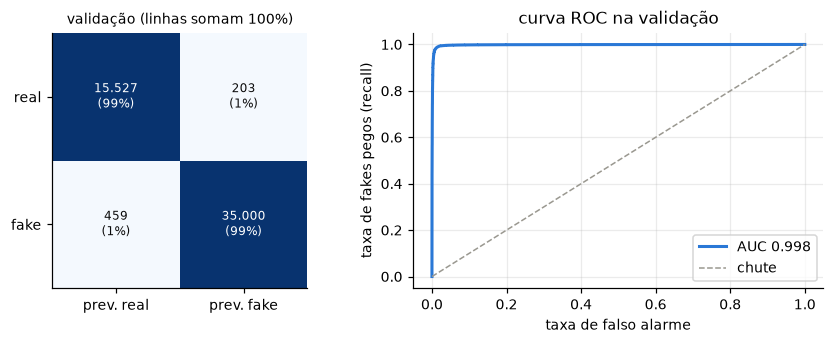

,n real,n fake,acurácia,recall fake,AUC,EER,falso alarme
dfadd,8710.0,31800.0,0.997877,0.998082,0.999949,0.002641,0.002870
shiftyspeech,1157.0,3471.0,0.919836,0.917891,0.979992,0.078220,0.074330
codecfake_plus,164.0,188.0,0.616477,0.398936,0.722139,0.326868,0.134146
librispeech,5699.0,0.0,0.987717,NaN,NaN,NaN,0.012283


In [29]:
y_val, p_val, _ = prever(val_loader)
RES = {"validação": {"tipo": "validação", "n no banco": len(df[df.split == "val"]), **metricas(y_val, p_val)}}
display(pd.DataFrame(RES).T[["n amostra", "n real", "n fake", "acurácia", "precisão", "recall fake",
                             "F1", "AUC", "EER", "falso alarme"]])

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), gridspec_kw={"width_ratios": [1, 1.2]})
desenhar_confusao(axes[0], y_val, p_val, "validação (linhas somam 100%)")
fpr, tpr, _ = roc_curve(y_val, p_val)
axes[1].plot(fpr, tpr, color=CAT[0], lw=2, label=f"AUC {roc_auc_score(y_val, p_val):.3f}")
axes[1].plot([0, 1], [0, 1], color="#9a9890", ls="--", lw=1, label="chute")
axes[1].set_xlabel("taxa de falso alarme")
axes[1].set_ylabel("taxa de fakes pegos (recall)")
axes[1].set_title("curva ROC na validação")
axes[1].legend()
plt.tight_layout()
plt.show()

por_fonte_val = pd.DataFrame({s: metricas(y_val[val_df.source_dataset == s], p_val[val_df.source_dataset == s])
                              for s in val_df.source_dataset.unique()}).T
display(por_fonte_val[["n real", "n fake", "acurácia", "recall fake", "AUC", "EER", "falso alarme"]])

**Conclusão:** na validação o modelo parece quase perfeito (EER 1,3%, AUC 0,998), mas ela é quase toda DFADD (EER 0,26% nele). No ShiftySpeech a EER já sobe para **7,8%** e no CodecFake+ (geradores de codec, de demos que não estão no treino) para **32,7%**: mesmo "em casa", quando o tipo de gerador muda, o desempenho cai muito. O limiar da EER ficou em **0,039**, bem longe de 0,5: o modelo dá notas muito baixas aos reais da validação, e qualquer real um pouco diferente passa do limiar e vira falso alarme (é o que aparece nos testes).

### 7.4 Amostras dos bancos de teste

**O que faz:** sorteia até `TEST_MAX_PER_CLASS` áudios de cada classe em cada banco de teste e mostra o tamanho de cada amostra.
**Por quê:** os bancos têm até 153 mil áudios; uma amostra limitada mantém o teste em poucos minutos, e o tamanho fica informado para saber o quanto confiar em cada número.

In [30]:
partes = []
for src in TESTES:
    for lab in (0, 1):
        g = teste_full[(teste_full.source_dataset == src) & (teste_full.label == lab)]
        if len(g):
            partes.append(g.sample(min(len(g), TEST_MAX_PER_CLASS), random_state=SEED))
teste_df = pd.concat(partes).reset_index(drop=True)

TAM = teste_df.groupby("source_dataset")["label"].agg(
    real=lambda s: int((s == 0).sum()), fake=lambda s: int((s == 1).sum())).reindex(TESTES)
TAM["amostra"] = TAM["real"] + TAM["fake"]
TAM["no banco"] = TAB_TESTE["áudios"]
TAM["% fake na amostra"] = (100 * TAM["fake"] / TAM["amostra"]).round(1)
TAM["% fake no banco"] = TAB_TESTE["% fake"]
TAM.insert(0, "tipo", [TIPO[s] for s in TESTES])
display(TAM)
print(f"Total: {fmt(len(teste_df))} áudios de teste (recorte central de {CROP_S:.0f} s).")

,tipo,real,fake,amostra,no banco,% fake na amostra,% fake no banco
source_dataset,,,,,,,
in_the_wild,principal,5000,5000,10000,31779,50.0,37.2
llamapartialspoof,principal,5000,5000,10000,140616,50.0,92.5
brspeech_df,principal (pt),1320,5000,6320,7907,79.1,83.3
asvspoof2019_la,secundário,5000,5000,10000,71237,50.0,89.7
asvspoof2021_df,secundário,5000,5000,10000,152955,50.0,96.4
coraa,falso alarme pt-BR,5000,0,5000,12350,0.0,0.0


Total: 51.320 áudios de teste (recorte central de 4 s).


### 7.5 Rodar o teste (uma única vez)

**O que faz:** passa todos os áudios de teste pelo modelo congelado, num só `DataLoader`, e guarda a probabilidade de fake de cada um.
**Por quê:** rodar uma vez só, com o checkpoint já escolhido, garante que nenhum resultado de teste influenciou decisão nenhuma.

In [31]:
teste_ds = AudioDataset(teste_df.path, teste_df.label, teste_df.sample_rate, teste_df.duration_s,
                        crop_s=CROP_S, target_sr=SAMPLE_RATE, mode="center")
t0 = time.time()
y_te, p_te, _ = prever(DataLoader(teste_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                                  pin_memory=True))
teste_df["p_fake"] = p_te
print(f"{fmt(len(teste_df))} áudios avaliados em {(time.time() - t0) / 60:.1f} min")

51.320 áudios avaliados em 0.7 min


### 7.6 Tabela final por banco

**O que faz:** calcula as métricas de cada banco, junta com a validação e salva em `results/baseline_results.csv`. Também avisa quando um banco tem quase só uma classe.
**Por quê:** é a tabela que resume o baseline e que as próximas versões vão tentar superar.

In [32]:
for src in TESTES:
    g = teste_df[teste_df.source_dataset == src]
    nome = "asvspoof2019_la (eval)" if src == "asvspoof2019_la" else src
    RES[nome] = {"tipo": TIPO[src], "n no banco": int(TAB_TESTE.loc[src, "áudios"]),
                 **metricas(g.label.values, g.p_fake.values)}
TAB_RES = pd.DataFrame(RES).T
TAB_RES.index.name = "banco"
COLS = ["tipo", "n no banco", "n amostra", "n real", "n fake", "acurácia", "precisão", "recall fake", "F1",
        "AUC", "EER", "falso alarme"]
TAB_RES = TAB_RES[COLS]
TAB_RES.to_csv(RESULTS_CSV)
print(f"salvo em {RESULTS_CSV}")

vis = TAB_RES.copy()
for c in ["acurácia", "precisão", "recall fake", "F1", "EER", "falso alarme"]:
    vis[c] = vis[c].map(lambda v: "—" if pd.isna(v) else f"{100 * v:.1f}%")
vis["AUC"] = vis["AUC"].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
display(vis)

for src in TESTES:
    pf = TAB_TESTE.loc[src, "% fake"]
    if pf in (0, 100):
        print(f"⚠️ {src}: só tem {'reais' if pf == 0 else 'fakes'}. Precisão, recall, F1, AUC e EER não fazem "
              f"sentido; vale só a taxa de falso alarme (= 1 − acurácia).")
    elif min(pf, 100 - pf) < 10:
        print(f"⚠️ {src}: no banco original, {pf:.1f}% são fake. Na amostra as classes foram equilibradas pelo teto, "
              f"mas no banco inteiro 'sempre fake' teria {max(pf, 100 - pf):.1f}% de acurácia; olhe AUC e EER.")

salvo em results\baseline_results.csv


,tipo,n no banco,n amostra,n real,n fake,acurácia,precisão,recall fake,F1,AUC,EER,falso alarme
banco,,,,,,,,,,,,
validação,validação,51189,51189,15730,35459,98.7%,99.4%,98.7%,99.1%,0.998,1.3%,1.3%
in_the_wild,principal,31779,10000,5000,5000,42.7%,45.6%,76.6%,57.2%,0.211,72.2%,91.2%
llamapartialspoof,principal,140616,10000,5000,5000,55.1%,53.3%,82.9%,64.9%,0.563,45.4%,72.7%
brspeech_df,principal (pt),7907,6320,1320,5000,57.1%,96.1%,47.7%,63.8%,0.766,30.6%,7.4%
asvspoof2019_la (eval),secundário,71237,10000,5000,5000,83.2%,99.9%,66.6%,79.9%,0.971,6.9%,0.1%
asvspoof2021_df,secundário,152955,10000,5000,5000,62.6%,63.6%,59.2%,61.3%,0.685,35.3%,33.9%
coraa,falso alarme pt-BR,12350,5000,5000,0,58.4%,—,—,—,—,—,41.6%


⚠️ llamapartialspoof: no banco original, 92.5% são fake. Na amostra as classes foram equilibradas pelo teto, mas no banco inteiro 'sempre fake' teria 92.5% de acurácia; olhe AUC e EER.
⚠️ asvspoof2021_df: no banco original, 96.4% são fake. Na amostra as classes foram equilibradas pelo teto, mas no banco inteiro 'sempre fake' teria 96.4% de acurácia; olhe AUC e EER.
⚠️ coraa: só tem reais. Precisão, recall, F1, AUC e EER não fazem sentido; vale só a taxa de falso alarme (= 1 − acurácia).


### 7.7 Matrizes de confusão e curvas ROC

**O que faz:** uma matriz de confusão por banco (linhas somam 100%) e as curvas ROC de todos os bancos com as duas classes num gráfico só.
**Por quê:** a matriz mostra que tipo de erro domina em cada banco (falso alarme ou fake que escapa); a ROC compara a separação entre bancos sem depender do limiar.

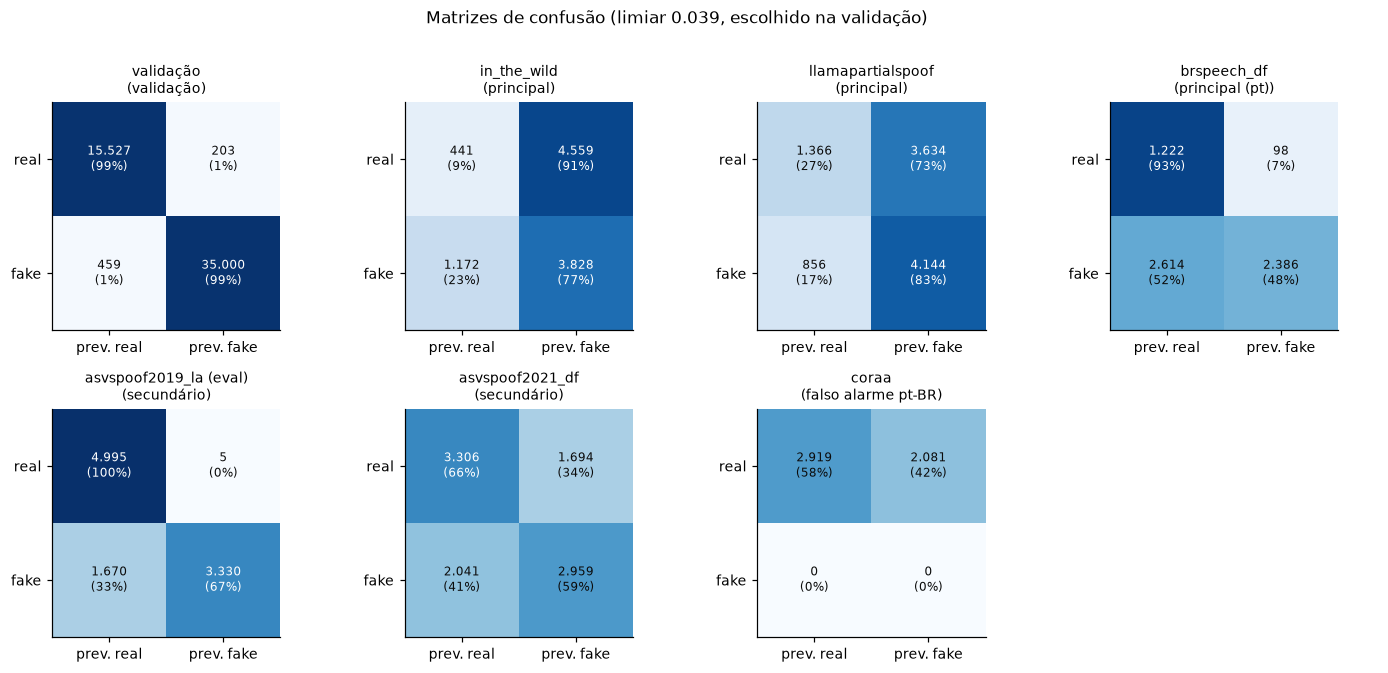

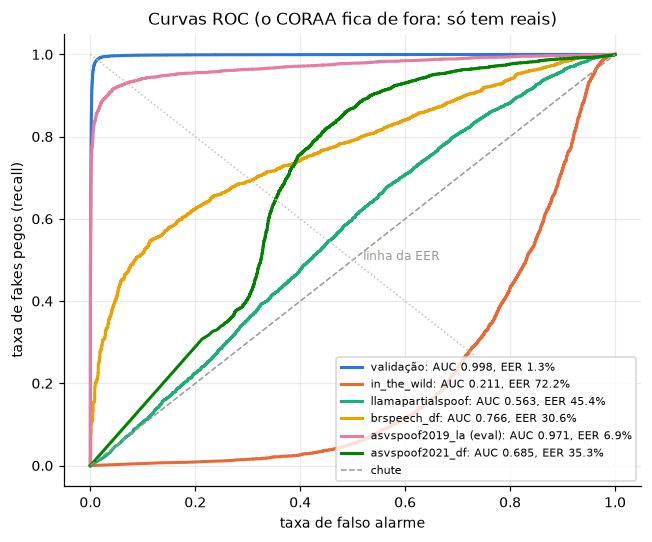

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
paineis = [("validação", y_val, p_val)] + [
    ("asvspoof2019_la (eval)" if s == "asvspoof2019_la" else s,
     teste_df.loc[teste_df.source_dataset == s, "label"].values,
     teste_df.loc[teste_df.source_dataset == s, "p_fake"].values) for s in TESTES]
for ax, (nome, y, p) in zip(axes.flat, paineis):
    desenhar_confusao(ax, y, p, f"{nome}\n({TIPO.get(nome.split(' ')[0], 'validação')})")
axes.flat[-1].axis("off")
plt.suptitle(f"Matrizes de confusão (limiar {LIMIAR:.3f}, escolhido na validação)", y=1.01)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for (nome, y, p), cor in zip([pn for pn in paineis if len(np.unique(pn[1])) == 2], CAT):
    fpr, tpr, _ = roc_curve(y, p)
    eer = eer_e_limiar(y, p)[0]
    ax.plot(fpr, tpr, color=cor, lw=2, label=f"{nome}: AUC {roc_auc_score(y, p):.3f}, EER {100 * eer:.1f}%")
ax.plot([0, 1], [0, 1], color="#9a9890", ls="--", lw=1, label="chute")
ax.plot([0, 1], [1, 0], color="#c3c2b7", ls=":", lw=1)
ax.text(0.52, 0.5, "linha da EER", color="#9a9890", fontsize=8)
ax.set_xlabel("taxa de falso alarme")
ax.set_ylabel("taxa de fakes pegos (recall)")
ax.set_title("Curvas ROC (o CORAA fica de fora: só tem reais)")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

### 7.8 Detalhes: fakes completos × parciais e geradores

**O que faz:** no LlamaPartialSpoof, separa a EER dos fakes completos e dos parciais (contra os mesmos reais) e, nos bancos com gerador conhecido, mostra o recall por gerador.
**Por quê:** um fake parcial tem só alguns trechos sintéticos, e o recorte de 4 s pode nem pegar esses trechos; e um recall médio pode esconder um gerador que passa quase sempre.

In [34]:
llama = teste_df[teste_df.source_dataset == "llamapartialspoof"]
linhas = []
for ft in ["full", "partial"]:
    g = llama[(llama.label == 0) | (llama.fake_type == ft)]
    if g.label.nunique() == 2:
        linhas.append({"fakes": ft, "n real": int((g.label == 0).sum()), "n fake": int((g.label == 1).sum()),
                       "AUC": roc_auc_score(g.label, g.p_fake), "EER": eer_e_limiar(g.label.values, g.p_fake.values)[0],
                       "recall fake": ((g.p_fake >= LIMIAR) & (g.label == 1)).sum() / max((g.label == 1).sum(), 1)})
display(pd.DataFrame(linhas).round(3))

ger = teste_df[(teste_df.label == 1) & (teste_df.generator != "unknown")].copy()
ger["pego"] = ger.p_fake >= LIMIAR
TAB_GER = (ger.groupby(["source_dataset", "generator"])["pego"].agg(["mean", "size"])
           .rename(columns={"mean": "recall fake", "size": "n fake"}))
TAB_GER["recall fake"] = (100 * TAB_GER["recall fake"]).round(1)
display(TAB_GER[TAB_GER.index.get_level_values(0) != "asvspoof2021_df"])
dfg = TAB_GER.loc["asvspoof2021_df"] if "asvspoof2021_df" in TAB_GER.index.get_level_values(0) else None
if dfg is not None and len(dfg):
    print(f"asvspoof2021_df: {len(dfg)} geradores na amostra; recall mediano {dfg['recall fake'].median():.1f}%, "
          f"pior {dfg['recall fake'].min():.1f}%, melhor {dfg['recall fake'].max():.1f}%")

,fakes,n real,n fake,AUC,EER,recall fake
0,full,5000,1324,0.587,0.435,0.866
1,partial,5000,3676,0.554,0.461,0.816


recall fake  n fake
source_dataset    generator                       
asvspoof2019_la   A07                 99.5     376
                  A08                 93.8     368
                  A09                100.0     392
                  A10                 45.9     399
                  A11                 59.8     391
                  A12                 62.3     398
                  A13                 33.9     395
                  A14                 69.3     384
                  A15                 24.4     390
                  A16                 99.5     368
                  A17                  1.1     359
                  A18                 90.9     396
                  A19                 85.7     384
brspeech_df       f5tts               72.2    1019
                  fish-speech         92.9    1019
                  toucantts           11.3     984
                  xtts                 6.0     995
                  yourtts             54.1     983
llamapartialspoof cosyvoice           90.4     811
                  elevenlab           79.7     851
                  gptsovits           78.3     866
                  ljjets              84.3     864
                  xttsv2              88.3     809
                  yourtts             76.7     799

asvspoof2021_df: 110 geradores na amostra; recall mediano 56.1%, pior 13.0%, melhor 100.0%


**Conclusões por banco de teste** (EER e AUC valem para o banco; acurácia e precisão, para a amostra):

- **In-the-Wild (principal): falhou, pior que o chute.** AUC 0,21 e EER 72%: o modelo ordena *ao contrário*, dando notas de fake mais altas aos reais (91% dos reais foram acusados). Hipótese, não verificada: os reais do In-the-Wild são áudios de internet com ruído, música e compressão, e o modelo aprendeu "gravação limpa de estúdio ou audiolivro = real", então todo áudio "sujo" parece fake. **Não invertemos a nota:** isso seria usar o teste para tomar uma decisão.
- **LlamaPartialSpoof (principal): falhou, quase chute.** AUC 0,56 e EER 45%. Ele pega 83% dos fakes, mas acusa 73% dos reais (LibriTTS). Fakes completos (EER 43,5%) e parciais (46,1%) ficam parecidos, então o problema não é só o recorte perder o trecho falso: o modelo não reconhece esses geradores modernos (ElevenLabs, XTTS, CosyVoice…) nem esses reais.
- **BRSpeech-DF (principal, pt): parcial.** AUC 0,77 e EER 31%, o melhor dos testes principais, com poucos falsos alarmes (7,4%). Mas o resultado é muito desigual entre geradores: fish-speech 93% e f5tts 72% de recall, contra **xtts 6%** e **toucantts 11%**. Não parece "bom demais", o que sugere que a reamostragem tirou o atalho da taxa de amostragem.
- **ASVspoof 2019 eval (secundário): o único que funcionou.** AUC 0,97 e EER 6,9%. É o mesmo corpus e as mesmas condições de gravação do treino (e talvez os mesmos locutores via VCTK), então mostra só que o modelo generaliza para *ataques* novos do mesmo mundo. Mesmo aqui, o A17 passa quase sempre (1% de recall) e o A15 e o A13 ficam entre 24% e 34%.
- **ASVspoof 2021 DF (secundário): fraco.** AUC 0,69 e EER 35%. São os mesmos tipos de ataque, mas com compressão de codec (MP3, AAC etc.), e isso já derruba o modelo (recall mediano por gerador de 56%).
- **CORAA (falso alarme pt-BR): inaceitável.** **41,6%** das vozes reais em português foram acusadas de fake. Num produto, 4 em cada 10 pessoas reais seriam marcadas como golpe.

## 8. Conclusões

**O que o baseline mostrou.** A CNN pequena (110 mil parâmetros, ~24 min de treino) aprende muito bem a separar real de fake **dentro dos bancos de treino** (EER 1,3% na validação, 0,26% no DFADD), mas **não generaliza para fora deles**. A queda é grande assim que muda a condição de gravação ou o tipo de gerador:

| banco | tipo | AUC | EER | leitura |
|:--|:--|--:|--:|:--|
| validação | — | 0,998 | 1,3% | em casa (quase todo DFADD) |
| asvspoof2019_la (eval) | secundário | 0,971 | 6,9% | mesmo mundo do treino, ataques novos |
| brspeech_df | principal (pt) | 0,766 | 30,6% | parcial; xtts e toucantts passam |
| asvspoof2021_df | secundário | 0,685 | 35,3% | a compressão de codec derruba |
| llamapartialspoof | principal | 0,563 | 45,4% | quase chute com geradores modernos |
| in_the_wild | principal | 0,211 | 72,2% | pior que chute: reais de internet parecem fake |
| coraa | falso alarme | — | — | 41,6% de reais em pt-BR acusados |

**Em quais bancos falhou:** nos três que mais se parecem com um golpe real, o In-the-Wild, o LlamaPartialSpoof e o CORAA (falso alarme), e no ASVspoof 2021 DF (codecs). A leitura mais provável é que o modelo aprendeu as **condições de gravação** dos bancos de treino (estúdio limpo e audiolivro = real) mais do que as **marcas da síntese**. Os sinais disso são o In-the-Wild invertido, a queda com codec no 2021 DF e o limiar de 0,039, que deixa qualquer real "diferente" do lado fake.

**Como produto anti-golpe, este baseline não serve:** acusaria a maioria das vozes reais vindas da internet. Ele cumpre o papel de baseline: dá a referência numérica e aponta o problema principal (domínio de gravação), que é exatamente o que os próximos passos atacam.

### Limitações conhecidas (do `docs/audit_report.md` e deste notebook)

- **VCTK compartilhado:** o ASVspoof 2019 eval e o ASVspoof 2021 DF podem ter locutores em comum com o treino (via DFADD). Medem geradores novos, não locutores novos.
- **BRSpeech-DF:** reais em 48 kHz e fakes em 24 kHz. A reamostragem elimina a diferença de banda acima de 8 kHz, mas não sabemos se há diferenças abaixo disso; o banco também mistura pt-BR e pt-PT sem indicação, e o locutor foi inferido do nome do arquivo.
- **Cobertura parcial:** só a parte 1 de 4 do ASVspoof 2021 DF e só o CoSG do CodecFake+ (o CoRS não foi baixado).
- **Validação sem ASVspoof 2019:** os ataques A01–A06 só aparecem no treino, e a validação é ~79% DFADD, então a EER de validação reflete principalmente o DFADD.
- **Atalho de fonte:** o LibriSpeech é só real; o modelo pode associar "som de audiolivro" a real.
- **Recorte de 4 s:** o modelo vê só 4 s do meio do áudio no teste; em fakes parciais o trecho sintético pode ficar de fora, e em áudios longos a decisão ignora o resto.
- **Amostras de teste:** até 5.000 por classe por banco, com proporções diferentes das originais (acurácia e precisão valem para a amostra).
- **ASVspoof 2021 DF:** ~40% dos FLAC só são lidos pelo `miniaudio` (o `soundfile` falha); conferimos que os dois dão as mesmas amostras nos arquivos que ambos leem, mas a auditoria original só leu os cabeçalhos.

### Próximos passos

1. **Augmentation de codec** (MP3, Opus, telefone 8 kHz), ruído e reverberação: golpes chegam por WhatsApp e telefone, não em FLAC limpo.
2. **Mais dados modernos** no treino (TTS e clonagem recentes, como os do LlamaPartialSpoof e do In-the-Wild, mas de outros bancos, para não contaminar os testes).
3. **Modelo maior** ou pré-treinado em fala (transfer learning da Aula 10, com um modelo de áudio em vez de ImageNet).
4. **Teste em pt-BR** mais amplo (ParlaSpoof-BR, MLAAD pt, FakeBrAccent) e medir o falso alarme em mais condições.
5. Avaliar o áudio **inteiro** (média de vários recortes de 4 s) em vez de só o central.

### Dúvidas de decisão (listadas em vez de decididas em silêncio)

1. **Limiar das métricas:** usamos o limiar da EER na validação, que ficou em 0,039 (longe do 0,5 esperado com treino 50/50) e explica boa parte dos falsos alarmes nos testes. Num produto real o limiar deveria ser escolhido pelo custo de cada erro (falso alarme incomoda o usuário; fake que escapa é o golpe).
2. **Amostra de teste com teto por classe** (até 5.000 de cada): equilibra as classes e muda a acurácia e a precisão em relação ao banco original. A alternativa seria uma amostra aleatória simples, que preserva a proporção mas tem poucos reais no LlamaPartialSpoof e no ASVspoof 2021 DF.
3. **Validação dominada pelo DFADD** (~79%): escolher o checkpoint pela EER média por fonte seria mais justo com ShiftySpeech e CodecFake+; mantivemos a EER da validação inteira por simplicidade.
4. **Ano de publicação** dos bancos: está "não documentado" porque nem o `datasets.yaml` nem o `audit_report.md` o trazem; dá para preencher a partir dos artigos de cada banco.
5. **Erro de leitura no ASVspoof 2021 DF**: vale atualizar o `audit_report.md` (que diz "0 ilegíveis", baseado só nos cabeçalhos) e decidir se o `miniaudio` fica como leitor oficial.
6. **Fakes parciais com recorte central:** contamos todo áudio parcial como fake mesmo que o recorte de 4 s não pegue o trecho sintético. A alternativa é usar os segmentos do arquivo de label para recortar onde há spoof (mas isso usaria informação que um detector real não tem).